# Intensity Data EDA

In [1]:
# Import the library to mount Google Drive
from google.colab import drive

import h5py
import torch
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split

In [2]:
# Mount the Google Drive at /content/drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
file_name = "RRUFF_low_bkg.hdf5"
file_path = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name}"
data_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"

## HDF5 Inspection

In [4]:
def print_hdf5_structure(name, obj):
    print(name)

with h5py.File(file_path, "r") as f:
    f.visititems(print_hdf5_structure)

pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt
pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt/2theta
pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt/intensity
pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt
pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt/2theta
pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt/intensity
pattern_Actinolite__R120010-9__Powder__DIF_File__10992.txt
pattern_Actinolite__R120010-9__Powder__DIF_File__10992.txt/2theta
pattern_Actinolite__R120010-9__Powder__DIF_File__10992.txt/intensity
pattern_Adelite__R060687-9__Powder__DIF_File__7037.txt
pattern_Adelite__R060687-9__Powder__DIF_File__7037.txt/2theta
pattern_Adelite__R060687-9__Powder__DIF_File__7037.txt/intensity
pattern_Adelite__R140962-9__Powder__DIF_File__12190.txt
pattern_Adelite__R140962-9__Powder__DIF_File__12190.txt/2theta
pattern_Adelite__R140962-9__Powder__DIF_File__12190.txt/intensity
pattern_Aegirine__R061093-9__Powder__DIF_File__11401.txt
patter

## Dataset Inspection

In [ ]:
# List of dataset paths you want to inspect
datasets = [
    "pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt",
    "pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt/2theta",
    "pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt/intensity",
    "pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt",
    "pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt/2theta",
    "pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt/intensity",
]

# Number of elements to preview from each dataset
n_preview = 10

with h5py.File(file_path, "r") as f:
    for dset_path in datasets:
        if dset_path not in f:
            print(f"\n⚠️ Not found: {dset_path}")
            continue

        obj = f[dset_path]

        if isinstance(obj, h5py.Group):
            print(f"\n📁 Group: {dset_path}")
            print(f"  Contains: {list(obj.keys())}")
        elif isinstance(obj, h5py.Dataset):
            data = obj[()]
            print(f"\n📂 Dataset: {dset_path}")
            print(f"  Shape: {data.shape}")
            print(f"  Dtype: {data.dtype}")
            print(f"  First {n_preview} values:\n  {data[:n_preview]}")
        else:
            print(f"\n❓ Unknown object type at: {dset_path}")


📁 Group: pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt
  Contains: ['2theta', 'intensity']

📂 Dataset: pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt/2theta
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [5.   5.01 5.02 5.03 5.04 5.05 5.06 5.07 5.08 5.09]

📂 Dataset: pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt/intensity
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

📁 Group: pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt
  Contains: ['2theta', 'intensity']

📂 Dataset: pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt/2theta
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [5.   5.01 5.02 5.03 5.04 5.05 5.06 5.07 5.08 5.09]

📂 Dataset: pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt/intensity
  Shape: (8501,)
  Dtype: float64
  First 10 values:
  [0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]


## First 50 patterns

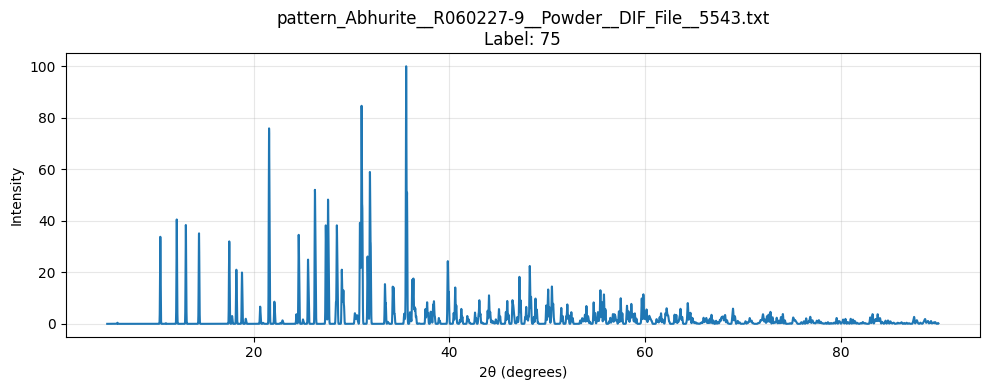

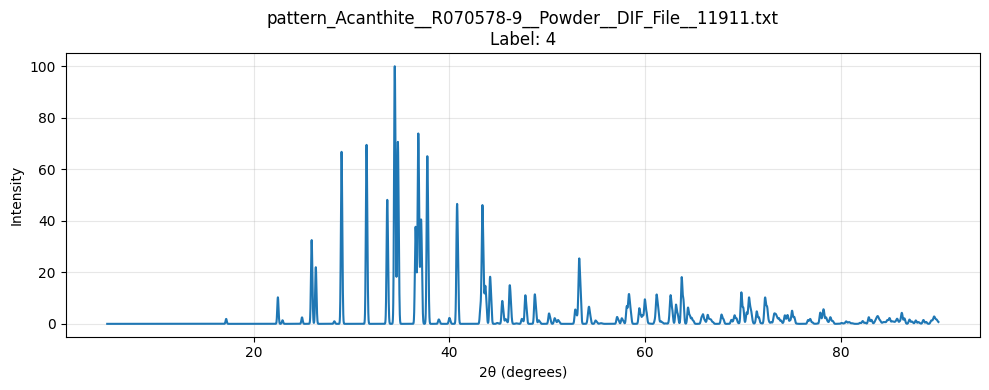

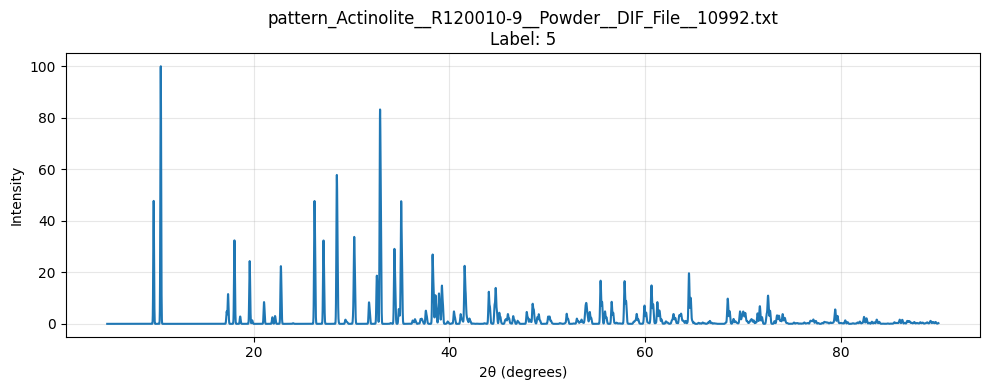

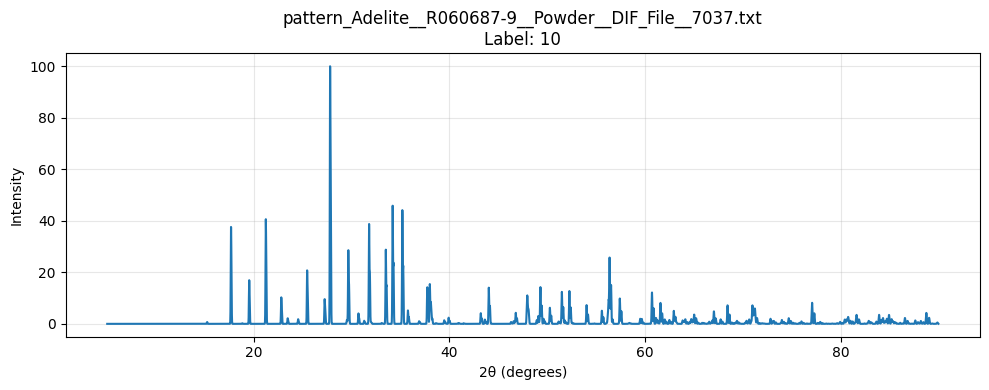

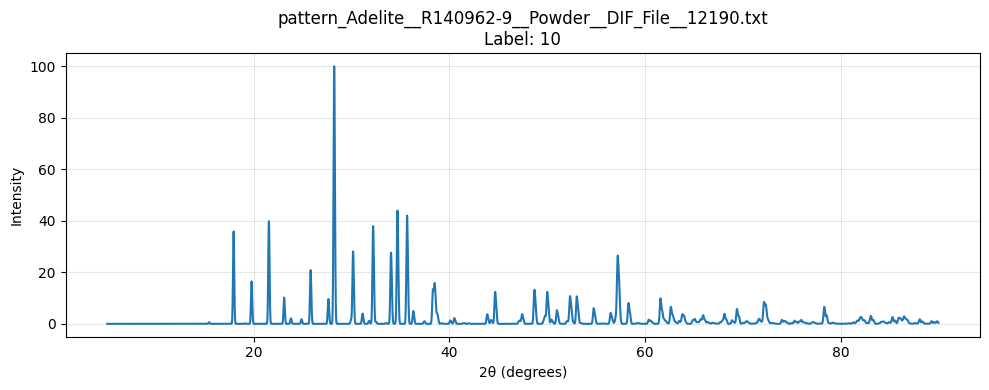

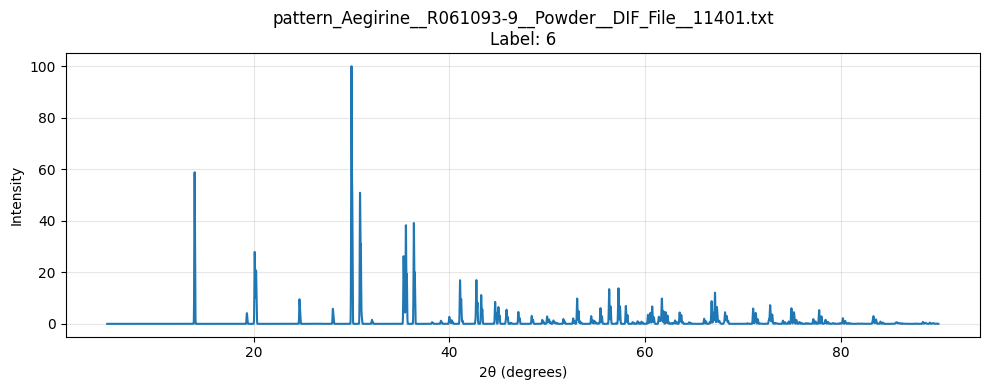

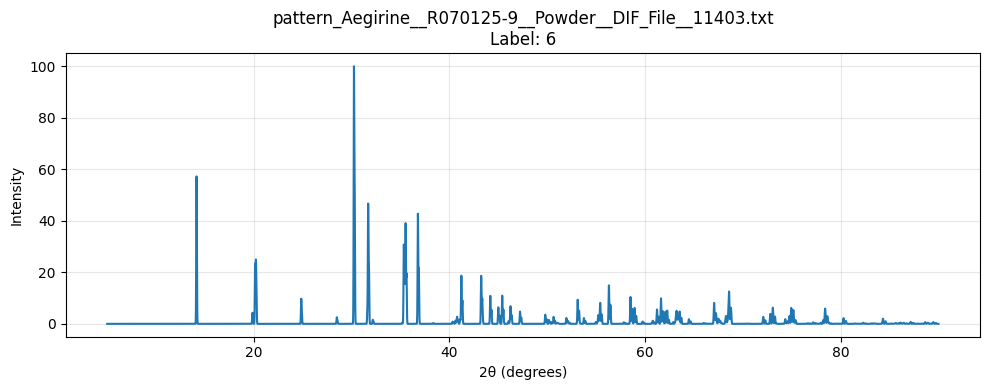

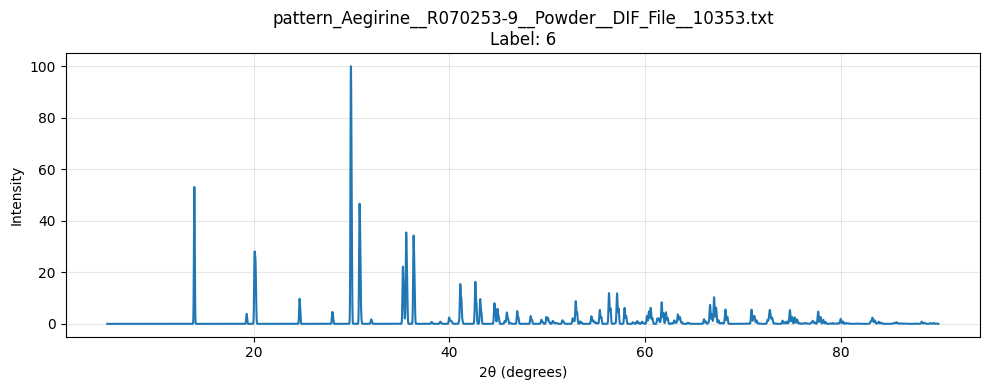

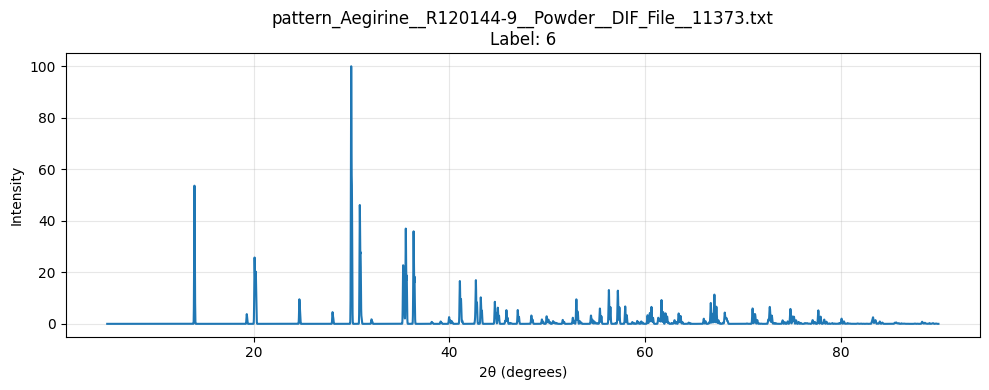

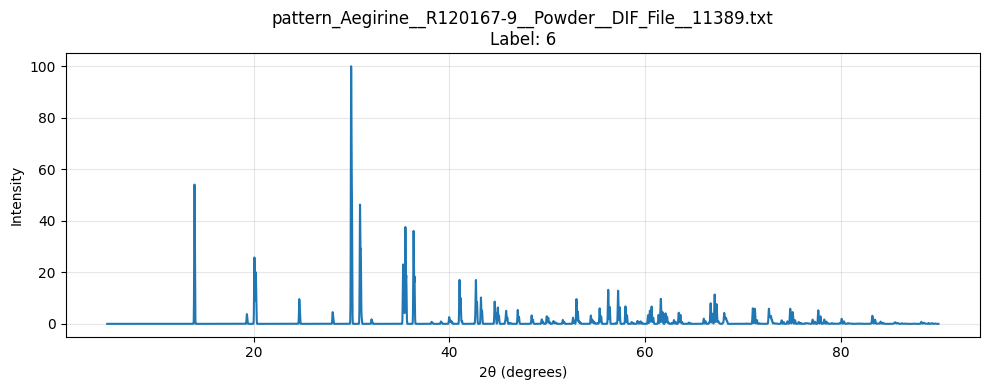

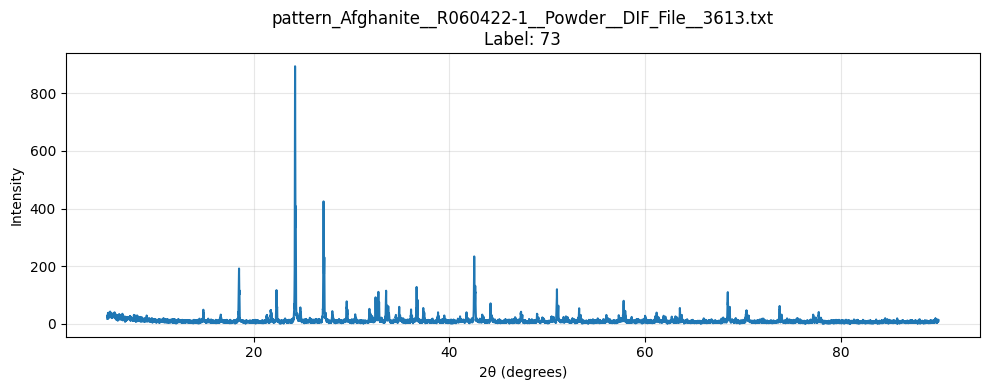

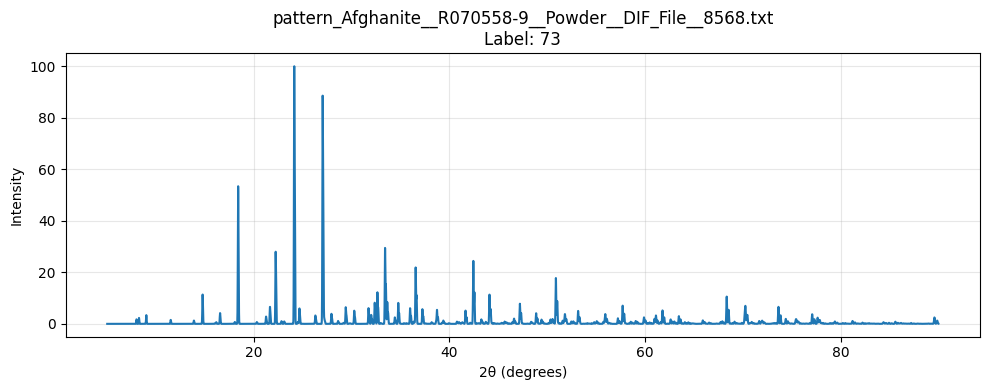

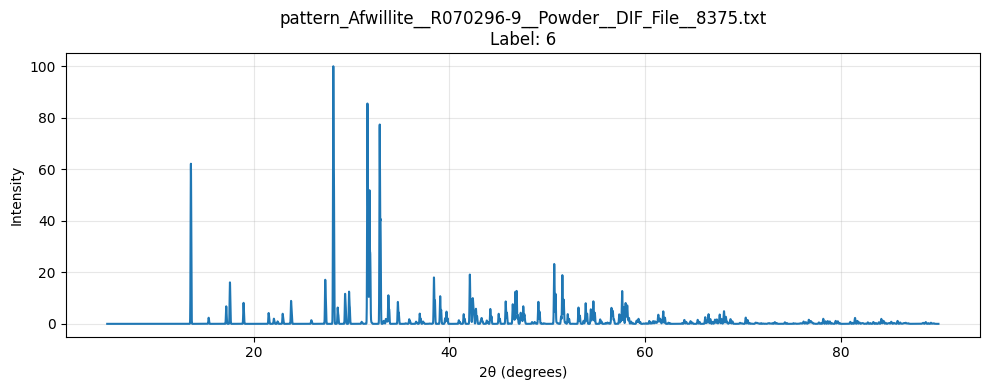

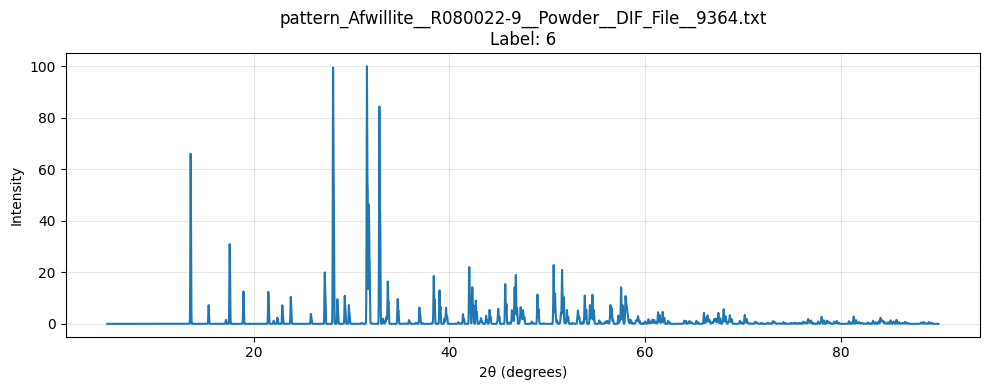

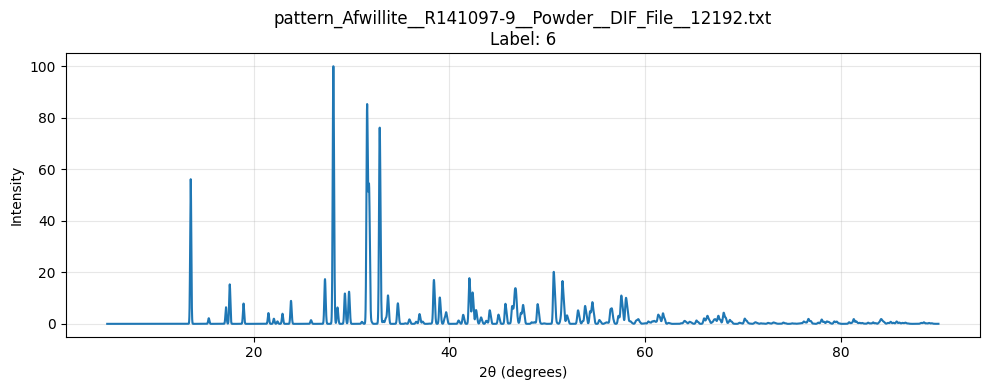

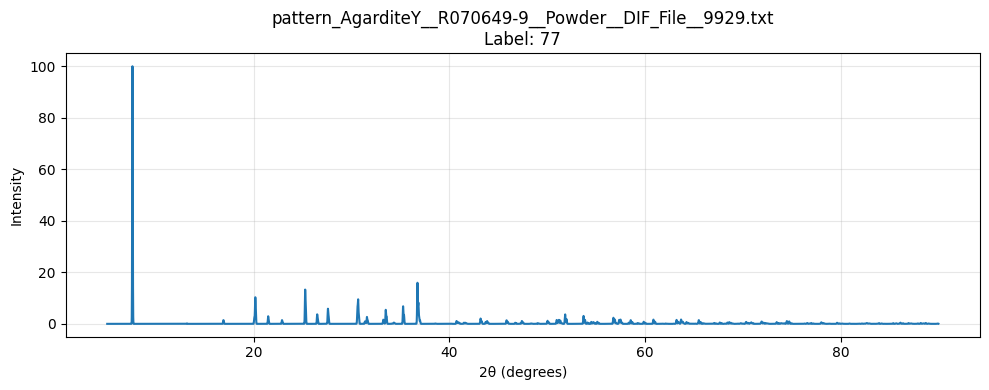

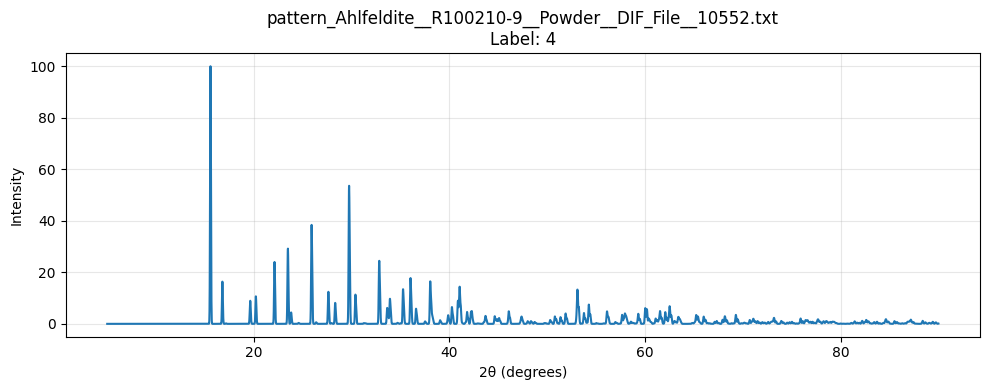

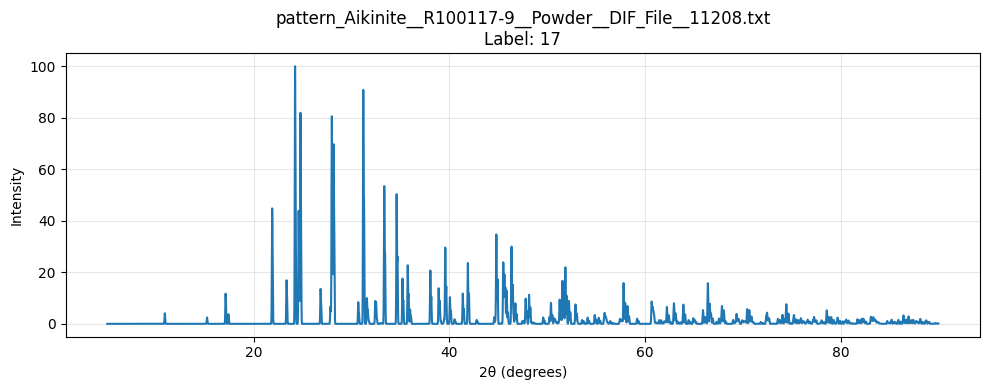

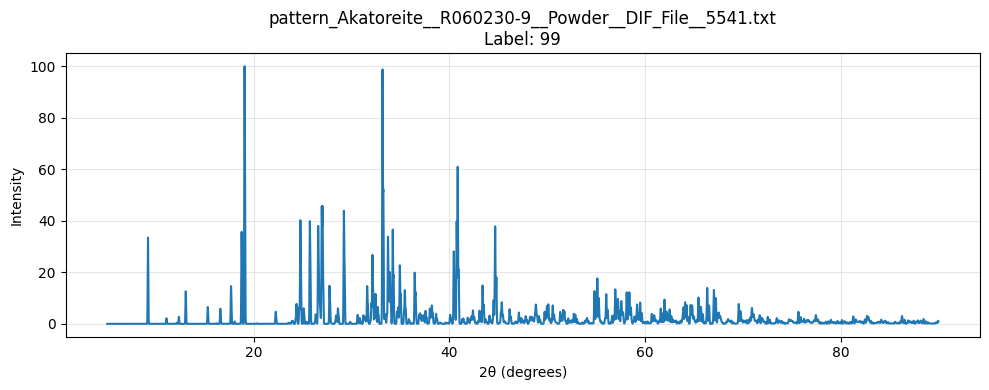

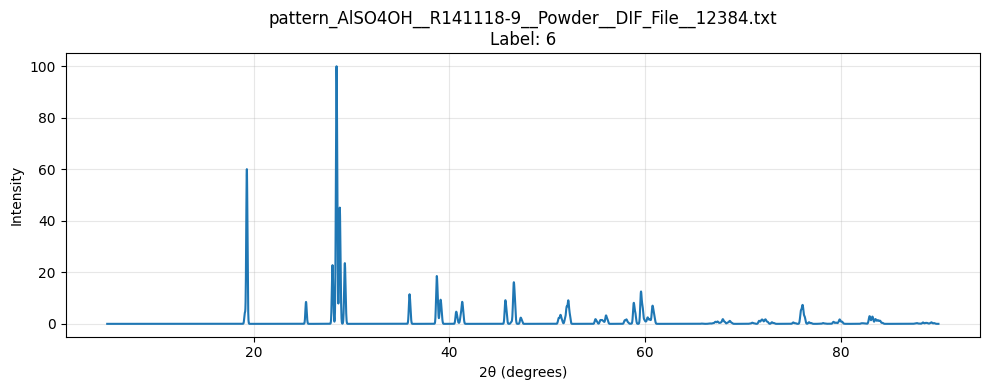

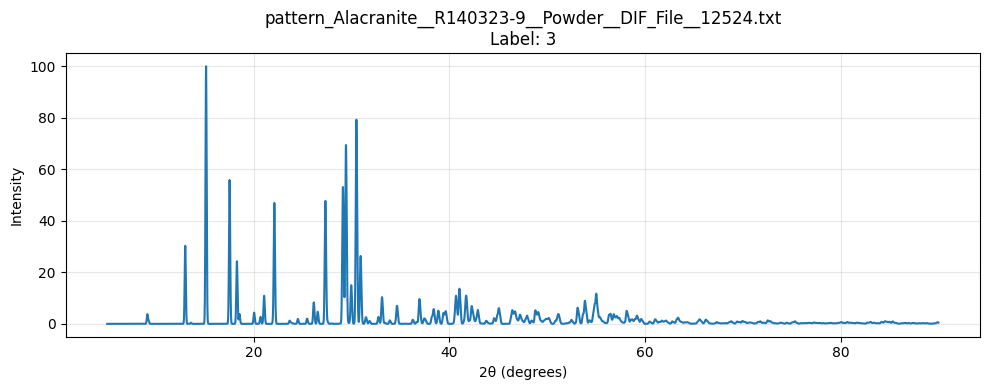

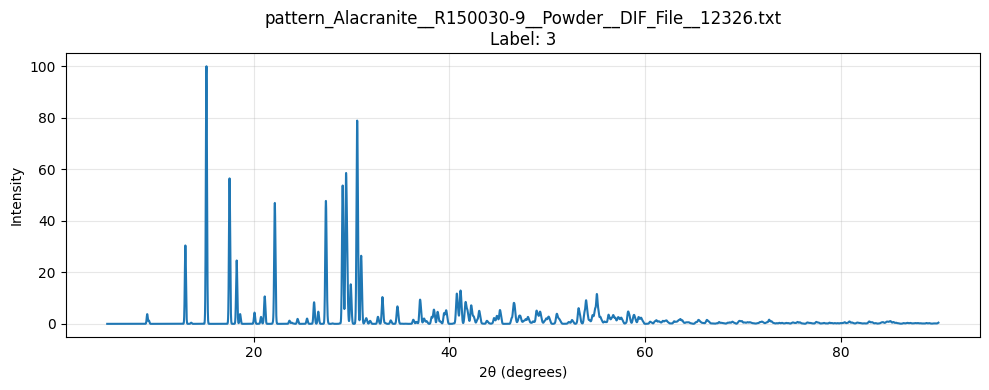

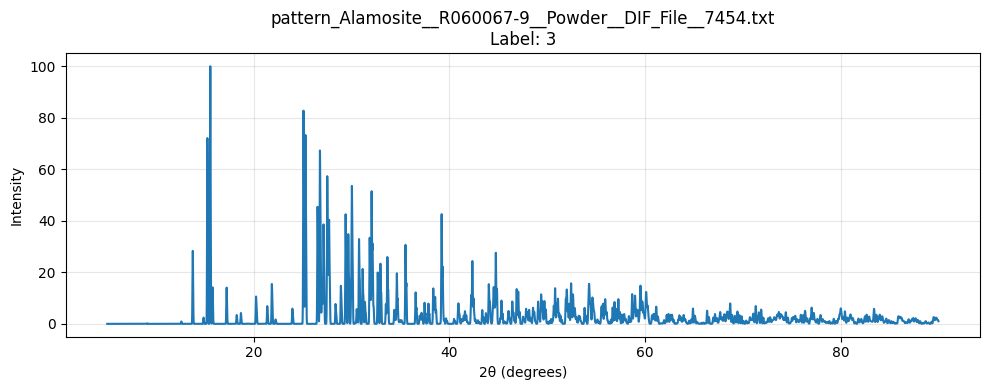

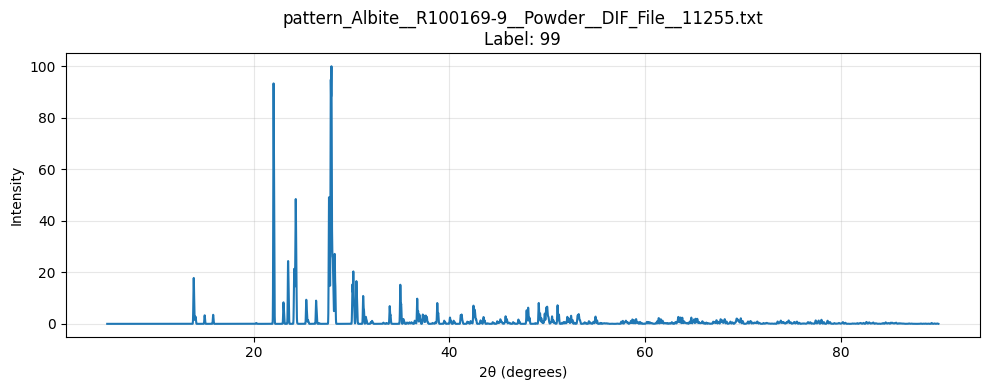

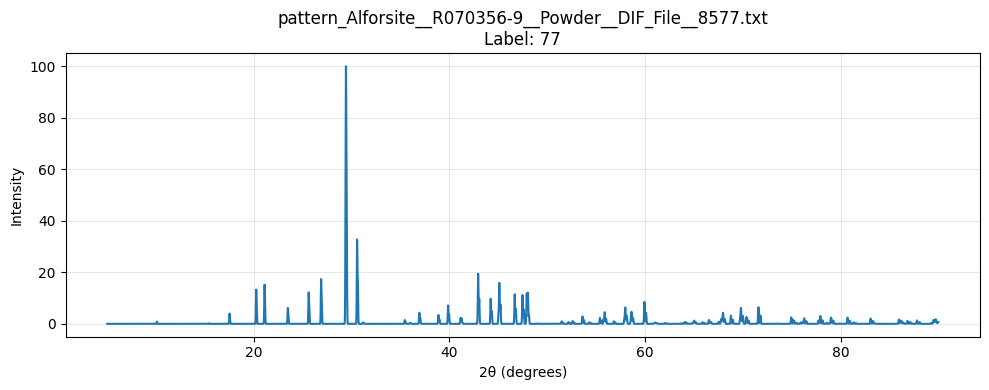

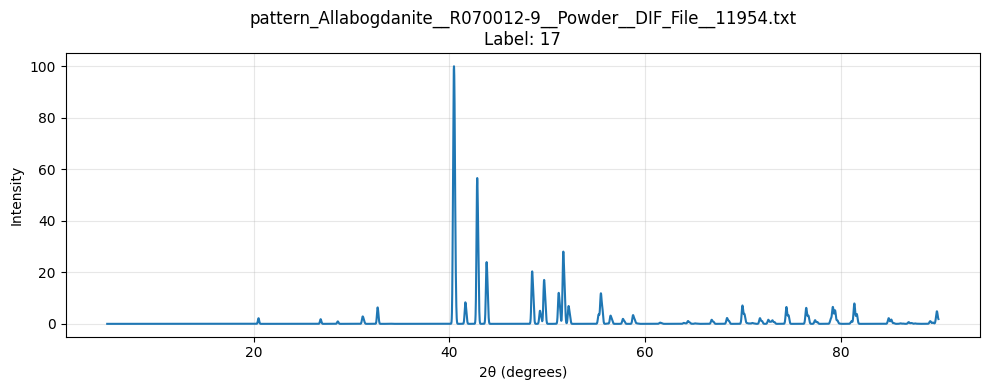

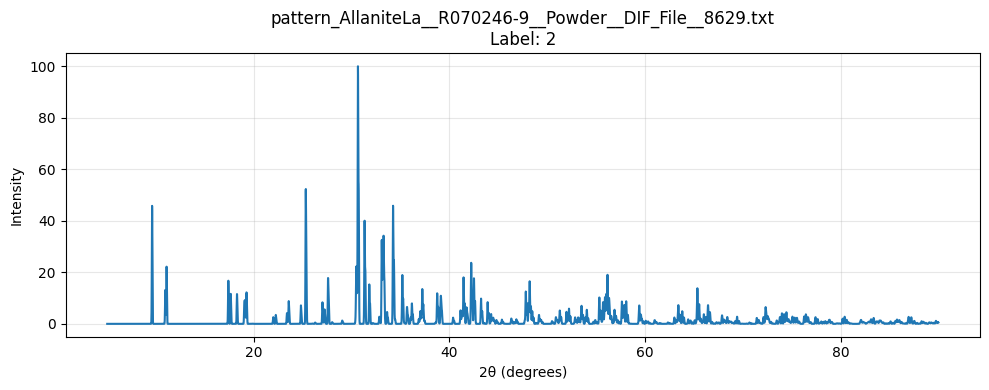

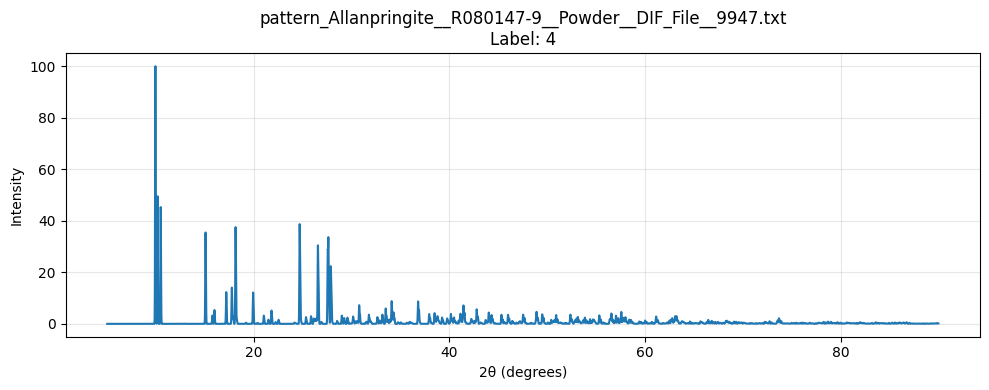

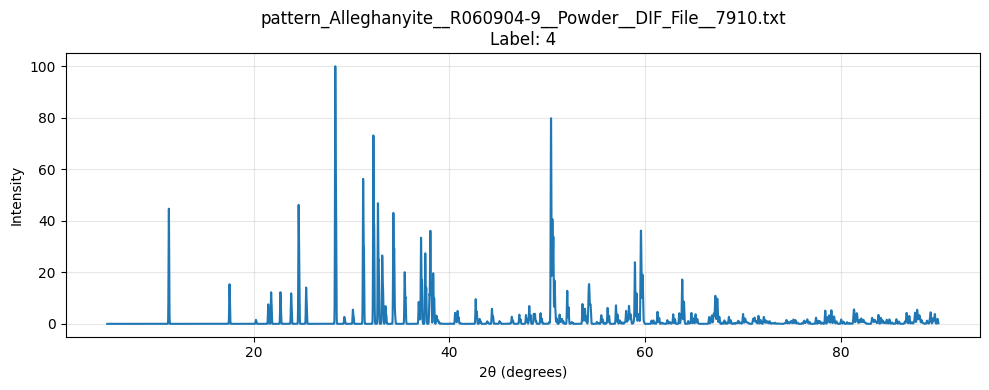

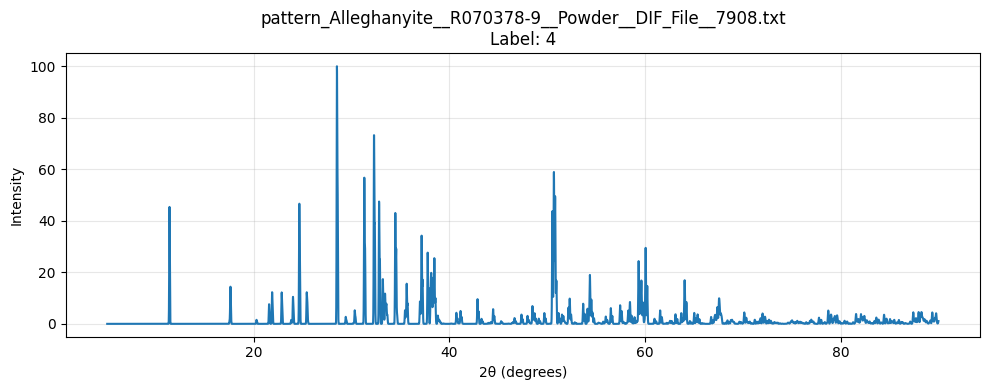

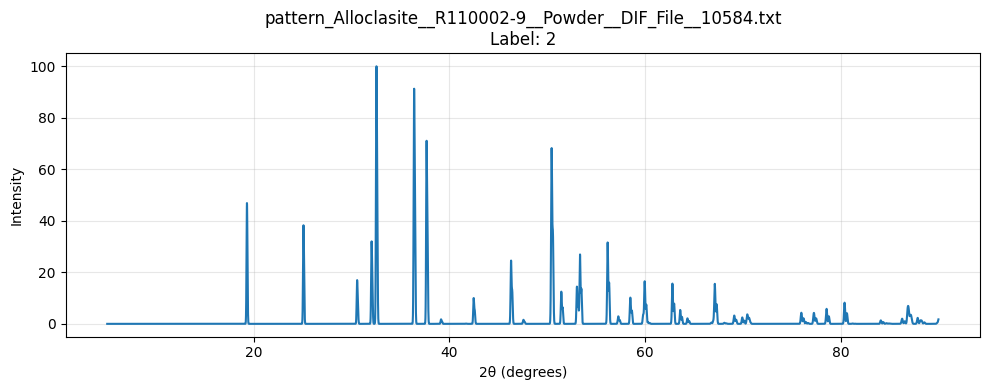

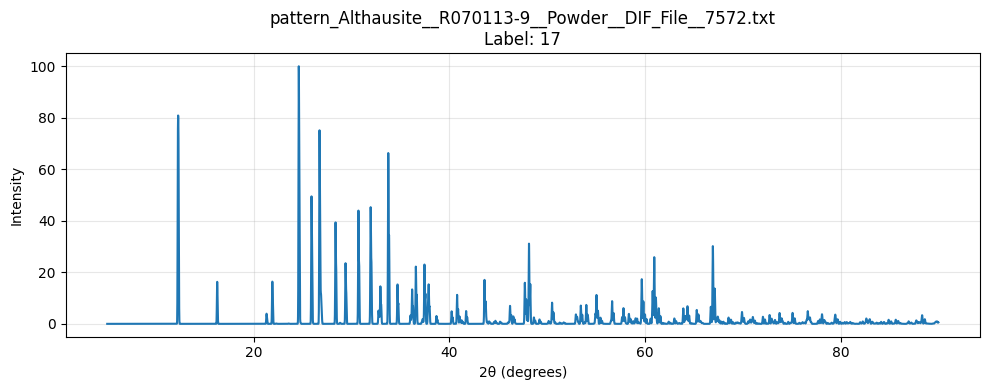

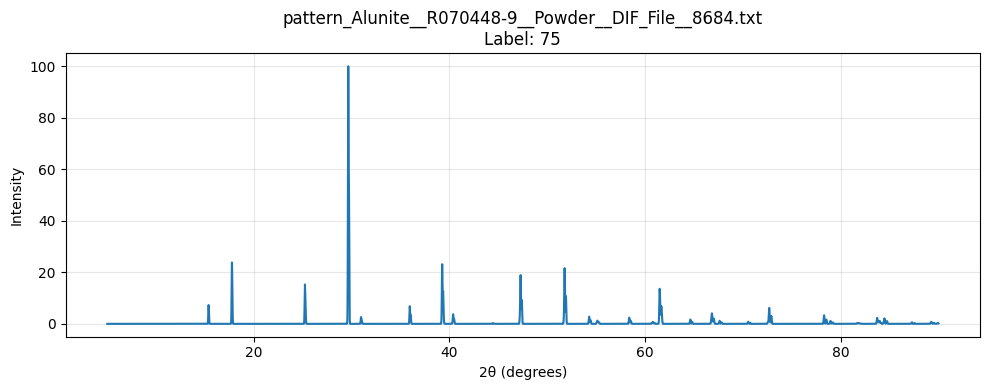

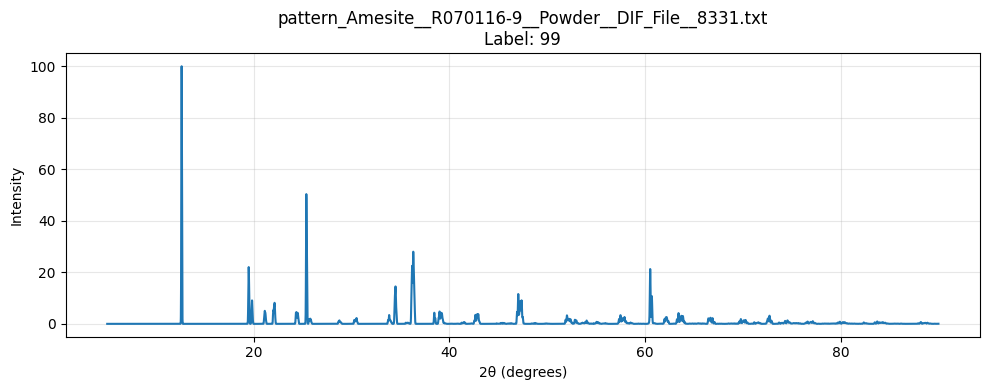

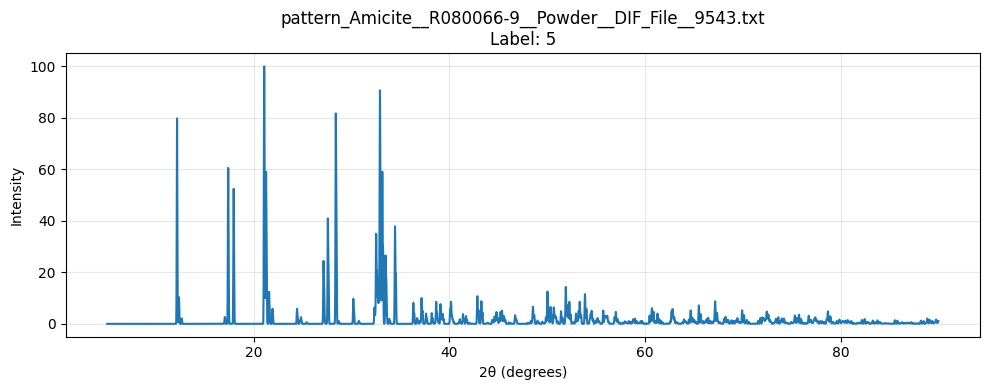

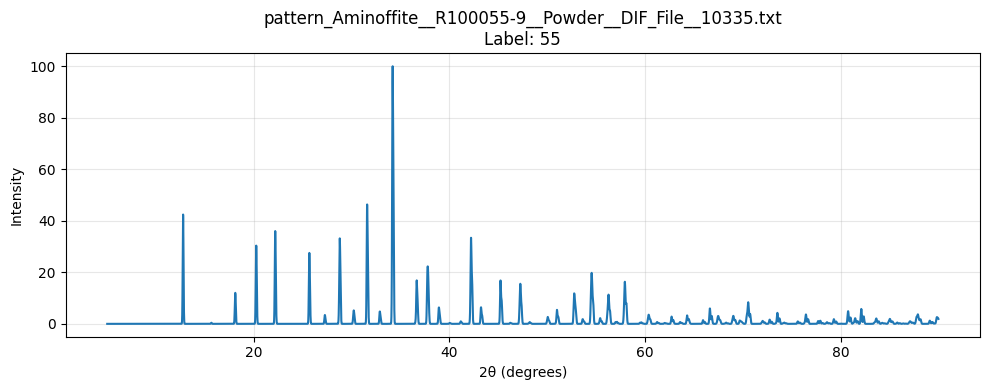

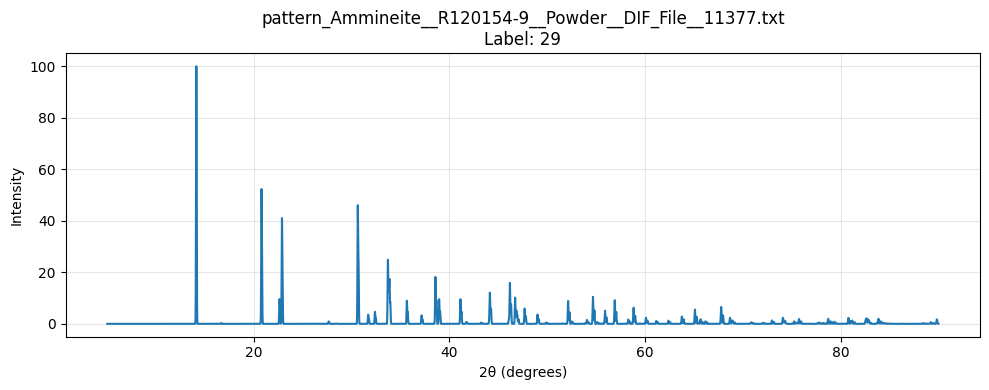

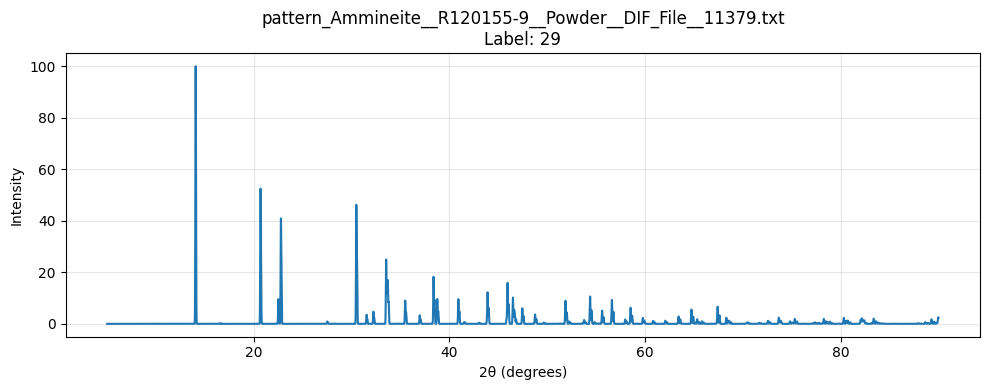

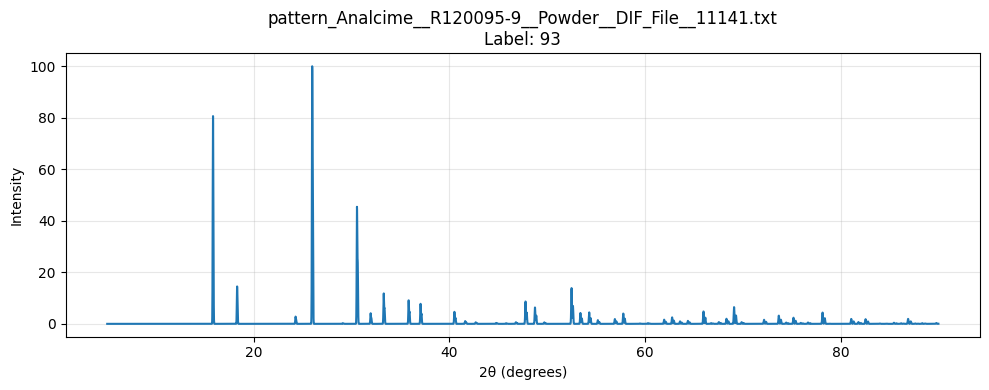

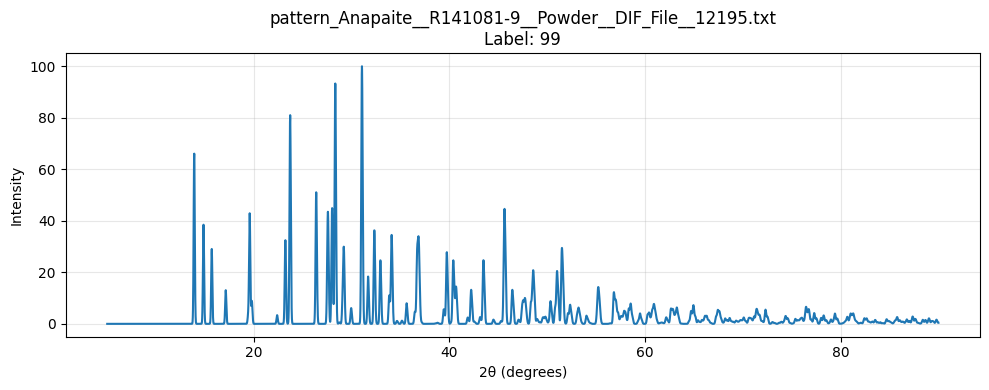

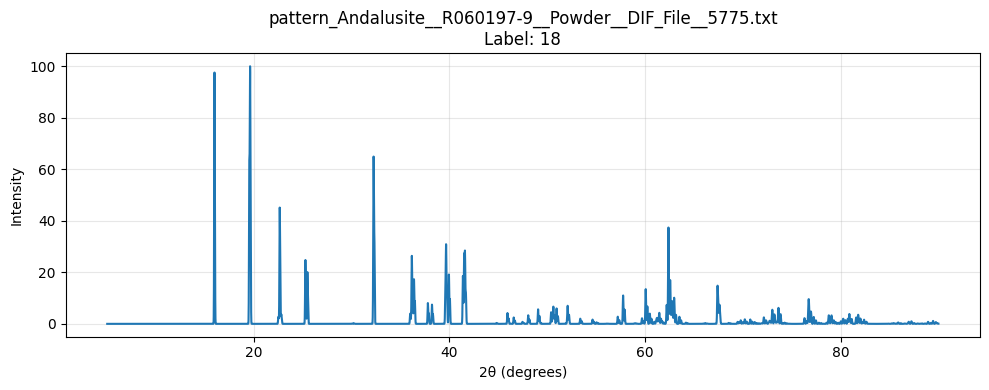

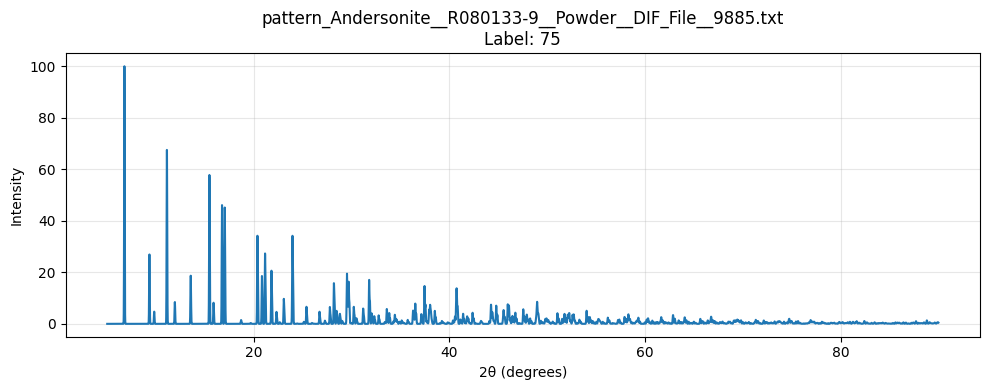

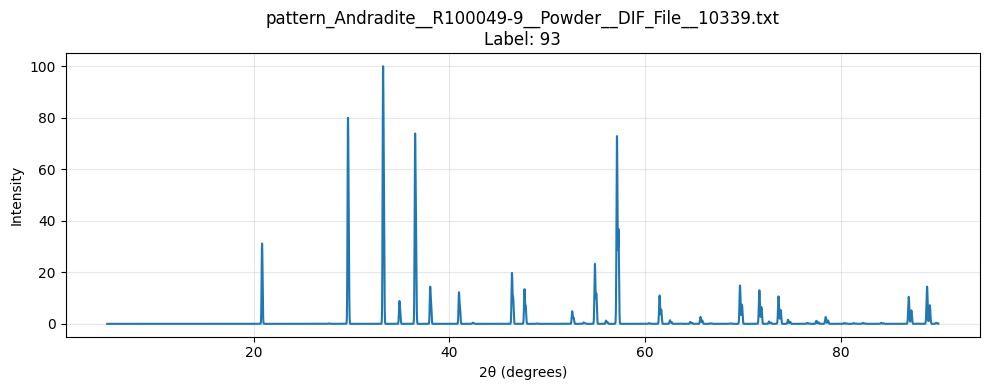

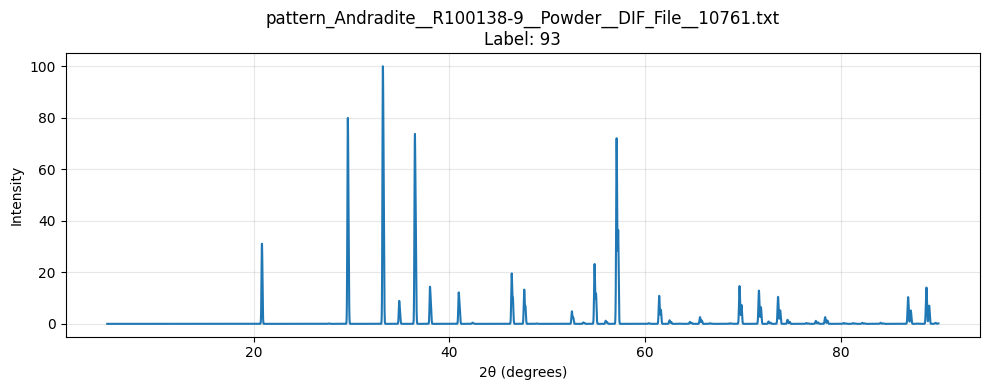

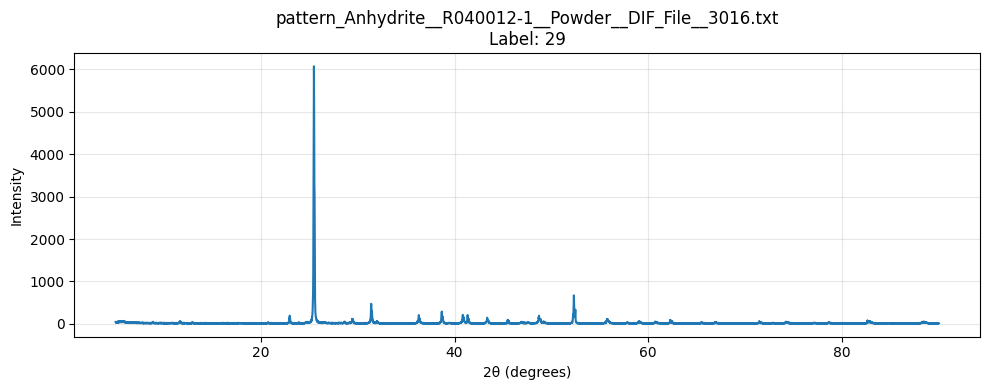

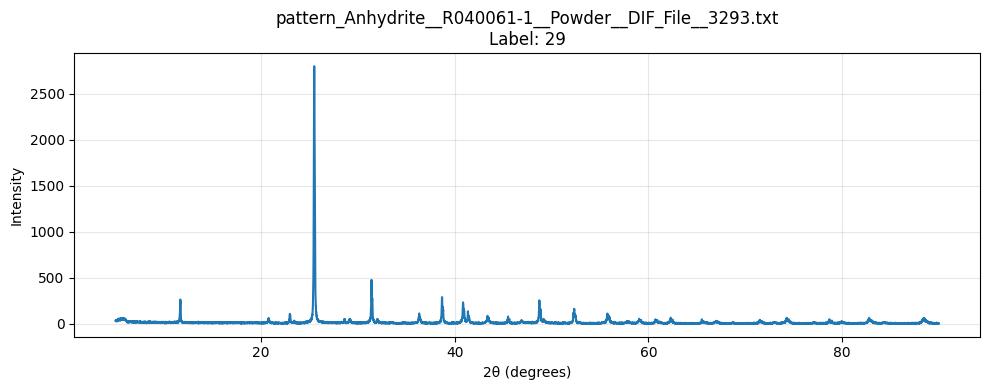

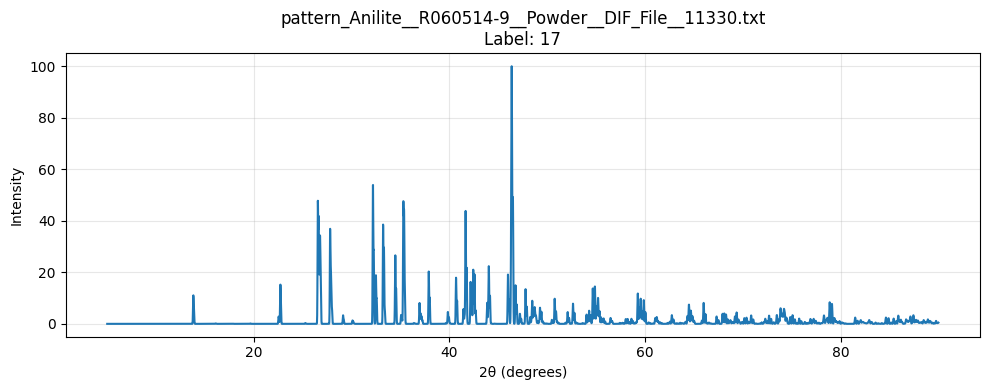

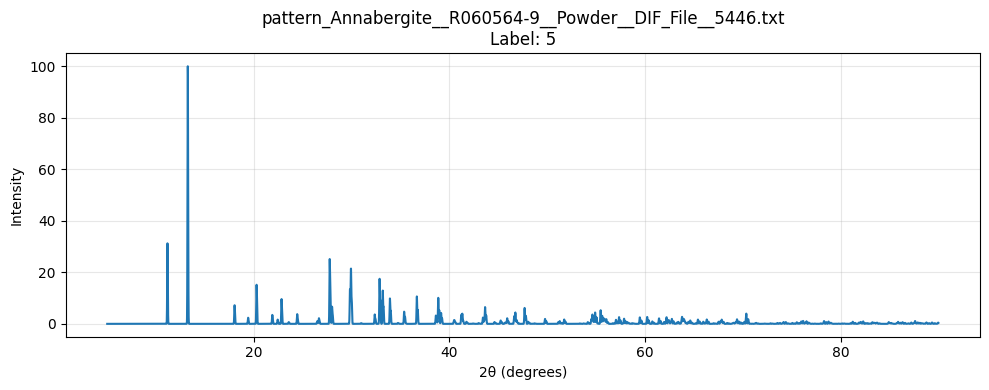

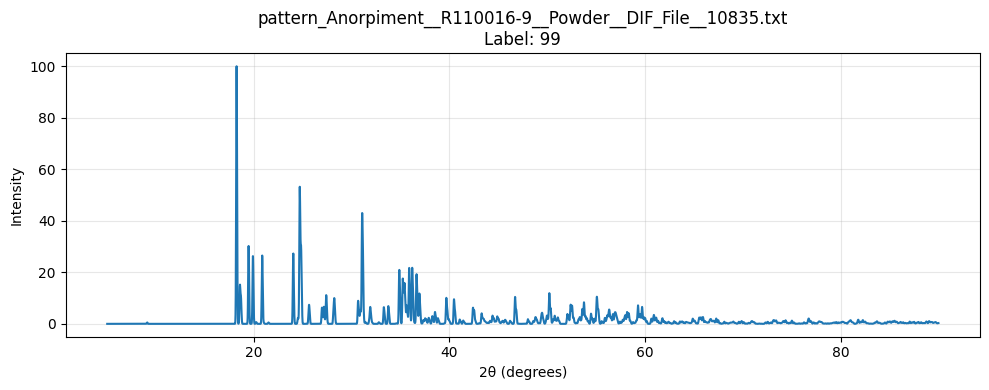

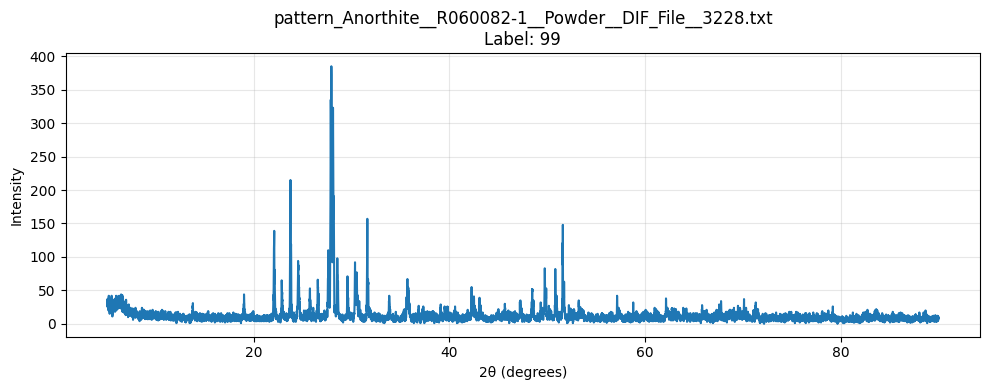

In [23]:
import h5py
import matplotlib.pyplot as plt

#file_path = "data.h5"   # <-- change this
N_PLOTS = 50

def normalize_attr(val):
    """Normalize HDF5 attribute to a Python scalar/string."""
    if hasattr(val, "shape") and val.shape == ():
        val = val.item()
    if isinstance(val, bytes):
        val = val.decode("utf-8")
    return val

plotted = 0

with h5py.File(file_path, "r") as f:
    for key, group in f.items():

        if plotted >= N_PLOTS:
            break

        if not isinstance(group, h5py.Group):
            continue

        if "2theta" not in group or "intensity" not in group:
            continue

        two_theta = group["2theta"][()]
        intensity = group["intensity"][()]

        if two_theta.shape != intensity.shape:
            print(f"⚠️ Shape mismatch in {key}")
            continue

        # --------------------------------------------------
        # EXACT ATTRIBUTE EXTRACTION YOU PROVIDED
        # --------------------------------------------------
        if "eg" in group.attrs:
            label = group.attrs["eg"]
        else:
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                label = attrs[0][1]
            else:
                print(f"No valid attribute found for {key}")
                continue

        label = normalize_attr(label)

        # --------------------------------------------------
        # PLOT
        # --------------------------------------------------
        plt.figure(figsize=(10, 4))
        plt.plot(two_theta, intensity)
        plt.xlabel("2θ (degrees)")
        plt.ylabel("Intensity")
        plt.title(f"{key}\nLabel: {label}")
        plt.grid(True, alpha=0.3)
        plt.tight_layout()
        plt.show()

        plotted += 1


## Global Statistics

In [ ]:
import h5py
import numpy as np
import pandas as pd

#file_path = "your_file.hdf5"  # <-- update this

records = []
dataset_count = 0
group_count = 0

def summarize_dataset(name, obj):
    """Collect dataset statistics into a list of dicts for DataFrame summary."""
    global dataset_count, group_count

    if isinstance(obj, h5py.Group):
        group_count += 1
        return

    if isinstance(obj, h5py.Dataset):
        dataset_count += 1
        data = obj[()]
        record = {
            "path": name,
            "shape": data.shape,
            "dtype": str(data.dtype),
            "size": data.size,
        }

        # Handle empty datasets
        if data.size == 0:
            record.update({
                "min": np.nan,
                "max": np.nan,
                "mean": np.nan,
                "std": np.nan,
                "nan_count": np.nan,
                "status": "empty",
            })
        elif np.issubdtype(data.dtype, np.number):
            nan_mask = np.isnan(data)
            nan_count = nan_mask.sum() if np.any(nan_mask) else 0
            record.update({
                "min": np.nanmin(data),
                "max": np.nanmax(data),
                "mean": np.nanmean(data),
                "std": np.nanstd(data),
                "nan_count": nan_count,
                "status": "ok" if nan_count == 0 else "contains_nans",
            })
        else:
            record.update({
                "min": np.nan,
                "max": np.nan,
                "mean": np.nan,
                "std": np.nan,
                "nan_count": np.nan,
                "status": "non-numeric",
            })

        records.append(record)

# --- Traverse file ---
with h5py.File(file_path, "r") as f:
    print(f"📘 Exploring file: {file_path}")
    f.visititems(summarize_dataset)

# --- Load into DataFrame ---
df = pd.DataFrame(records)

print("\n" + "="*80)
print(f"📊 Total groups (samples): {group_count}")
print(f"📊 Total datasets: {dataset_count}")
print("="*80)

# --- Display summary ---
print("\n🔍 DataFrame Summary:")
print(df.head())

# --- Example aggregate statistics ---
print("\n📈 Global Stats Summary:")
print(df[["min", "max", "mean", "std", "nan_count"]].describe())

# Optionally save to CSV for later analysis
# df.to_csv("hdf5_summary.csv", index=False)


📘 Exploring file: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg.hdf5

📊 Total groups (samples): 1248
📊 Total datasets: 2496

🔍 DataFrame Summary:
                                                path    shape    dtype  size  \
0  pattern_Abhurite__R060227-9__Powder__DIF_File_...  (8501,)  float64  8501   
1  pattern_Abhurite__R060227-9__Powder__DIF_File_...  (8501,)  float64  8501   
2  pattern_Acanthite__R070578-9__Powder__DIF_File...  (8501,)  float64  8501   
3  pattern_Acanthite__R070578-9__Powder__DIF_File...  (8501,)  float64  8501   
4  pattern_Actinolite__R120010-9__Powder__DIF_Fil...  (8501,)  float64  8501   

   min    max       mean        std  nan_count status  
0  5.0   90.0  47.500000  24.540273          0     ok  
1  0.0  100.0   2.145054   6.399756          0     ok  
2  5.0   90.0  47.500000  24.540273          0     ok  
3  0.0  100.0   2.802820   8.619971          0     ok  
4  5.0   90.0  47.500000  24.540273          0     o

## Aggregate Statistics for 2theta and Intensity

In [ ]:
import h5py
import numpy as np
import pandas as pd

records = []
dataset_count = 0
group_count = 0

def classify_dataset(name):
    """Classify dataset type based on path name."""
    lname = name.lower()
    if "2theta" in lname or "two_theta" in lname:
        return "2theta"
    elif "intensity" in lname:
        return "intensity"
    else:
        return "other"

def summarize_dataset(name, obj):
    """Collect dataset statistics into a list of dicts for DataFrame summary."""
    global dataset_count, group_count

    if isinstance(obj, h5py.Group):
        group_count += 1
        return

    if isinstance(obj, h5py.Dataset):
        dataset_count += 1
        data = obj[()]
        kind = classify_dataset(name)

        record = {
            "path": name,
            "kind": kind,
            "shape": data.shape,
            "dtype": str(data.dtype),
            "size": data.size,
        }

        # Handle empty datasets
        if data.size == 0:
            record.update({
                "min": np.nan,
                "max": np.nan,
                "mean": np.nan,
                "std": np.nan,
                "nan_count": np.nan,
                "status": "empty",
            })

        elif np.issubdtype(data.dtype, np.number):
            nan_mask = np.isnan(data)
            nan_count = nan_mask.sum() if np.any(nan_mask) else 0
            record.update({
                "min": np.nanmin(data),
                "max": np.nanmax(data),
                "mean": np.nanmean(data),
                "std": np.nanstd(data),
                "nan_count": nan_count,
                "status": "ok" if nan_count == 0 else "contains_nans",
            })

        else:
            record.update({
                "min": np.nan,
                "max": np.nan,
                "mean": np.nan,
                "std": np.nan,
                "nan_count": np.nan,
                "status": "non-numeric",
            })

        records.append(record)

# --- Traverse file ---
with h5py.File(file_path, "r") as f:
    print(f"📘 Exploring file: {file_path}")
    f.visititems(summarize_dataset)

# --- Load into DataFrame ---
df = pd.DataFrame(records)

print("\n" + "="*80)
print(f"📊 Total groups (samples): {group_count}")
print(f"📊 Total datasets: {dataset_count}")
print("="*80)

# --- Display preview ---
print("\n🔍 DataFrame Preview:")
print(df.head())

# ------------------------------------------------------------------
# 📈 Separate statistics for 2theta and intensity
# ------------------------------------------------------------------
for kind in ["2theta", "intensity"]:
    sub = df[df["kind"] == kind]

    print("\n" + "-"*80)
    print(f"📈 Aggregate statistics for {kind.upper()}")
    print(f"Datasets: {len(sub)}")

    if len(sub) == 0:
        print("⚠️ No datasets found")
        continue

    print(sub[["min", "max", "mean", "std", "nan_count"]].describe())

# --- Optional: inspect non-standard datasets ---
print("\n" + "-"*80)
print("📎 Non-2theta / Non-intensity datasets:")
print(df[df["kind"] == "other"][["path", "shape", "dtype", "status"]].head())

# Optionally save to CSV
# df.to_csv("hdf5_summary_with_2theta_intensity.csv", index=False)


📘 Exploring file: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg.hdf5

📊 Total groups (samples): 1248
📊 Total datasets: 2496

🔍 DataFrame Preview:
                                                path       kind    shape  \
0  pattern_Abhurite__R060227-9__Powder__DIF_File_...     2theta  (8501,)   
1  pattern_Abhurite__R060227-9__Powder__DIF_File_...  intensity  (8501,)   
2  pattern_Acanthite__R070578-9__Powder__DIF_File...     2theta  (8501,)   
3  pattern_Acanthite__R070578-9__Powder__DIF_File...  intensity  (8501,)   
4  pattern_Actinolite__R120010-9__Powder__DIF_Fil...     2theta  (8501,)   

     dtype  size  min    max       mean        std  nan_count status  
0  float64  8501  5.0   90.0  47.500000  24.540273          0     ok  
1  float64  8501  0.0  100.0   2.145054   6.399756          0     ok  
2  float64  8501  5.0   90.0  47.500000  24.540273          0     ok  
3  float64  8501  0.0  100.0   2.802820   8.619971          0     ok  
4

## Global Summary Statistics

In [ ]:
import h5py
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# CONFIG
# ------------------------------------------------------------------
#file_path = "data.h5"   # <-- change this

records = []
dataset_count = 0
group_count = 0

# Global aggregate accumulator for ALL intensities
global_intensity = {
    "count": 0,
    "sum": 0.0,
    "sum_sq": 0.0,
    "min": np.inf,
    "max": -np.inf,
    "nan_count": 0,
}

# ------------------------------------------------------------------
# HELPERS
# ------------------------------------------------------------------
def classify_dataset(name):
    """Classify dataset type based on path name."""
    lname = name.lower()
    if "2theta" in lname or "two_theta" in lname:
        return "2theta"
    elif "intensity" in lname:
        return "intensity"
    else:
        return "other"


def summarize_dataset(name, obj):
    """Collect per-dataset stats + global intensity aggregates."""
    global dataset_count, group_count, global_intensity

    if isinstance(obj, h5py.Group):
        group_count += 1
        return

    if not isinstance(obj, h5py.Dataset):
        return

    dataset_count += 1
    data = obj[()]
    kind = classify_dataset(name)

    record = {
        "path": name,
        "kind": kind,
        "shape": data.shape,
        "dtype": str(data.dtype),
        "size": data.size,
    }

    # --------------------------------------------------------------
    # EMPTY DATASET
    # --------------------------------------------------------------
    if data.size == 0:
        record.update({
            "min": np.nan,
            "max": np.nan,
            "mean": np.nan,
            "std": np.nan,
            "nan_count": np.nan,
            "status": "empty",
        })
        records.append(record)
        return

    # --------------------------------------------------------------
    # NUMERIC DATASET
    # --------------------------------------------------------------
    if np.issubdtype(data.dtype, np.number):
        nan_mask = np.isnan(data)
        nan_count = int(nan_mask.sum()) if np.any(nan_mask) else 0

        record.update({
            "min": float(np.nanmin(data)),
            "max": float(np.nanmax(data)),
            "mean": float(np.nanmean(data)),
            "std": float(np.nanstd(data)),
            "nan_count": nan_count,
            "status": "ok" if nan_count == 0 else "contains_nans",
        })

        # ----------------------------------------------------------
        # GLOBAL AGGREGATE (INTENSITY ONLY)
        # ----------------------------------------------------------
        if kind == "intensity":
            data_clean = np.nan_to_num(
                data, nan=0.0, posinf=0.0, neginf=0.0
            )

            global_intensity["count"] += data_clean.size
            global_intensity["sum"] += data_clean.sum()
            global_intensity["sum_sq"] += np.square(data_clean).sum()
            global_intensity["min"] = min(
                global_intensity["min"], data_clean.min()
            )
            global_intensity["max"] = max(
                global_intensity["max"], data_clean.max()
            )
            global_intensity["nan_count"] += nan_count

    # --------------------------------------------------------------
    # NON-NUMERIC DATASET
    # --------------------------------------------------------------
    else:
        record.update({
            "min": np.nan,
            "max": np.nan,
            "mean": np.nan,
            "std": np.nan,
            "nan_count": np.nan,
            "status": "non-numeric",
        })

    records.append(record)

# ------------------------------------------------------------------
# TRAVERSE HDF5 FILE
# ------------------------------------------------------------------
with h5py.File(file_path, "r") as f:
    print(f"📘 Exploring file: {file_path}")
    f.visititems(summarize_dataset)

# ------------------------------------------------------------------
# LOAD INTO DATAFRAME
# ------------------------------------------------------------------
df = pd.DataFrame(records)

print("\n" + "=" * 80)
print(f"📊 Total groups (samples): {group_count}")
print(f"📊 Total datasets: {dataset_count}")
print("=" * 80)

print("\n🔍 DataFrame Preview:")
print(df.head())

# ------------------------------------------------------------------
# GLOBAL AGGREGATE STATISTICS (ALL INTENSITIES)
# ------------------------------------------------------------------
if global_intensity["count"] > 0:
    mean = global_intensity["sum"] / global_intensity["count"]
    var = (
        global_intensity["sum_sq"] / global_intensity["count"]
        - mean ** 2
    )
    std = np.sqrt(var)

    print("\n" + "=" * 80)
    print("📊 GLOBAL INTENSITY STATISTICS (ALL DATASETS COMBINED)")
    print("=" * 80)
    print(f"Total values : {global_intensity['count']}")
    print(f"Min          : {global_intensity['min']}")
    print(f"Max          : {global_intensity['max']}")
    print(f"Mean         : {mean}")
    print(f"Std          : {std}")
    print(f"NaN count    : {global_intensity['nan_count']}")
else:
    print("\n⚠️ No intensity datasets found")

# ------------------------------------------------------------------
# OPTIONAL: INSPECT NON-STANDARD DATASETS
# ------------------------------------------------------------------
print("\n" + "-" * 80)
print("📎 Non-2theta / Non-intensity datasets:")
print(df[df["kind"] == "other"][["path", "shape", "dtype", "status"]].head())

# ------------------------------------------------------------------
# OPTIONAL: SAVE TO CSV
# ------------------------------------------------------------------
# df.to_csv("hdf5_per_dataset_summary.csv", index=False)
#

📘 Exploring file: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg.hdf5

📊 Total groups (samples): 1248
📊 Total datasets: 2496

🔍 DataFrame Preview:
                                                path       kind    shape  \
0  pattern_Abhurite__R060227-9__Powder__DIF_File_...     2theta  (8501,)   
1  pattern_Abhurite__R060227-9__Powder__DIF_File_...  intensity  (8501,)   
2  pattern_Acanthite__R070578-9__Powder__DIF_File...     2theta  (8501,)   
3  pattern_Acanthite__R070578-9__Powder__DIF_File...  intensity  (8501,)   
4  pattern_Actinolite__R120010-9__Powder__DIF_Fil...     2theta  (8501,)   

     dtype  size  min    max       mean        std  nan_count status  
0  float64  8501  5.0   90.0  47.500000  24.540273          0     ok  
1  float64  8501  0.0  100.0   2.145054   6.399756          0     ok  
2  float64  8501  5.0   90.0  47.500000  24.540273          0     ok  
3  float64  8501  0.0  100.0   2.802820   8.619971          0     ok  
4

## Global Intensity Distribution

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# collect all intensity values
all_intensity_values = []

with h5py.File(file_path, "r") as f:
    for path in df[df["kind"] == "intensity"]["path"]:
        data = f[path][()]
        all_intensity_values.append(data.ravel())

all_intensity_values = np.concatenate(all_intensity_values)

print(f"Total intensity points: {all_intensity_values.size}")
print(f"Min intensity: {np.min(all_intensity_values)}")
print(f"Max intensity: {np.max(all_intensity_values)}")

# plot histogram
plt.figure(figsize=(10, 5))
plt.hist(all_intensity_values, bins=200)
plt.xlabel("Intensity")
plt.ylabel("Count")
plt.title("Global Intensity Distribution")
plt.grid(True)
plt.tight_layout()
plt.show()


NameError: name 'df' is not defined

## Number of patterns with intensity spec > 1000

In [ ]:
import h5py
import numpy as np

#file_path = "data.h5"   # <-- change this
THRESHOLD = 1000

pattern_count = 0
patterns_above_threshold = 0

def classify_dataset(name):
    lname = name.lower()
    if "intensity" in lname:
        return "intensity"
    return "other"


def check_pattern(name, obj):
    global pattern_count, patterns_above_threshold

    if not isinstance(obj, h5py.Dataset):
        return

    if classify_dataset(name) != "intensity":
        return

    data = obj[()]

    # Skip empty or non-numeric datasets
    if data.size == 0 or not np.issubdtype(data.dtype, np.number):
        return

    pattern_count += 1

    # Check if ANY intensity exceeds threshold
    if np.nanmax(data) > THRESHOLD:
        patterns_above_threshold += 1


with h5py.File(file_path, "r") as f:
    print(f"📘 Scanning file: {file_path}")
    f.visititems(check_pattern)

print("\n" + "=" * 80)
print("📊 INTENSITY PATTERN THRESHOLD CHECK")
print("=" * 80)
print(f"Threshold value              : {THRESHOLD}")
print(f"Total intensity patterns     : {pattern_count}")
print(f"Patterns with value > {THRESHOLD}: {patterns_above_threshold}")
print(
    f"Fraction                     : "
    f"{patterns_above_threshold / pattern_count:.4f}"
    if pattern_count > 0 else "N/A"
)


📘 Scanning file: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg.hdf5

📊 INTENSITY PATTERN THRESHOLD CHECK
Threshold value              : 1000
Total intensity patterns     : 1248
Patterns with value > 1000: 18
Fraction                     : 0.0144


## Outlier Inspection


INTENSITY GLOBAL MAX
Path       : pattern_Anhydrite__R040012-1__Powder__DIF_File__3016.txt/intensity
Max value  : 6076.0
Max index  : 2047
Shape      : (8500,)


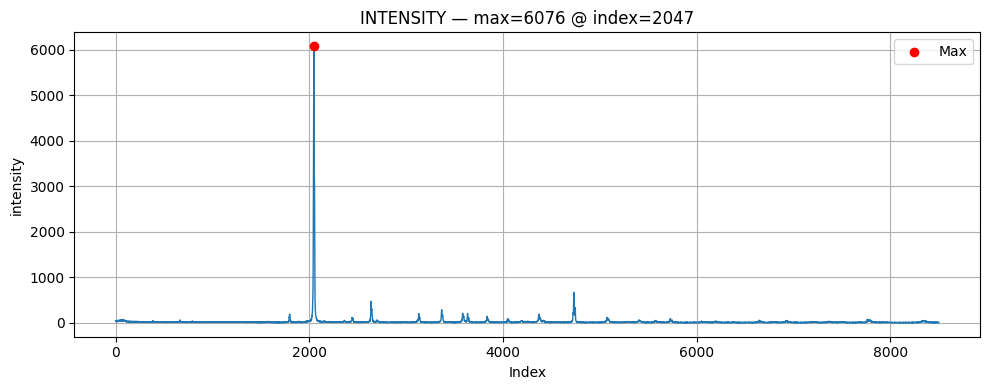

In [ ]:
import matplotlib.pyplot as plt

def find_max_and_plot(kind):
    sub = df[df["kind"] == kind]

    if sub.empty:
        print(f"No datasets found for kind='{kind}'")
        return

    # Find row with global max
    row = sub.loc[sub["max"].idxmax()]
    path = row["path"]

    # Load the actual dataset
    with h5py.File(file_path, "r") as f:
        data = f[path][()]

    # Index of maximum value
    max_idx = int(np.nanargmax(data))
    max_val = np.nanmax(data)

    print("\n" + "="*80)
    print(f"{kind.upper()} GLOBAL MAX")
    print(f"Path       : {path}")
    print(f"Max value  : {max_val}")
    print(f"Max index  : {max_idx}")
    print(f"Shape      : {data.shape}")
    print("="*80)

    # Plot
    plt.figure(figsize=(10, 4))
    plt.plot(data, lw=1)
    plt.scatter(max_idx, max_val, color="red", zorder=5, label="Max")
    plt.title(f"{kind.upper()} — max={max_val:.4g} @ index={max_idx}")
    plt.xlabel("Index")
    plt.ylabel(kind)
    plt.legend()
    plt.grid(True)
    plt.tight_layout()
    plt.show()


# ---- Run for each type ----
#find_max_and_plot("2theta")
find_max_and_plot("intensity")


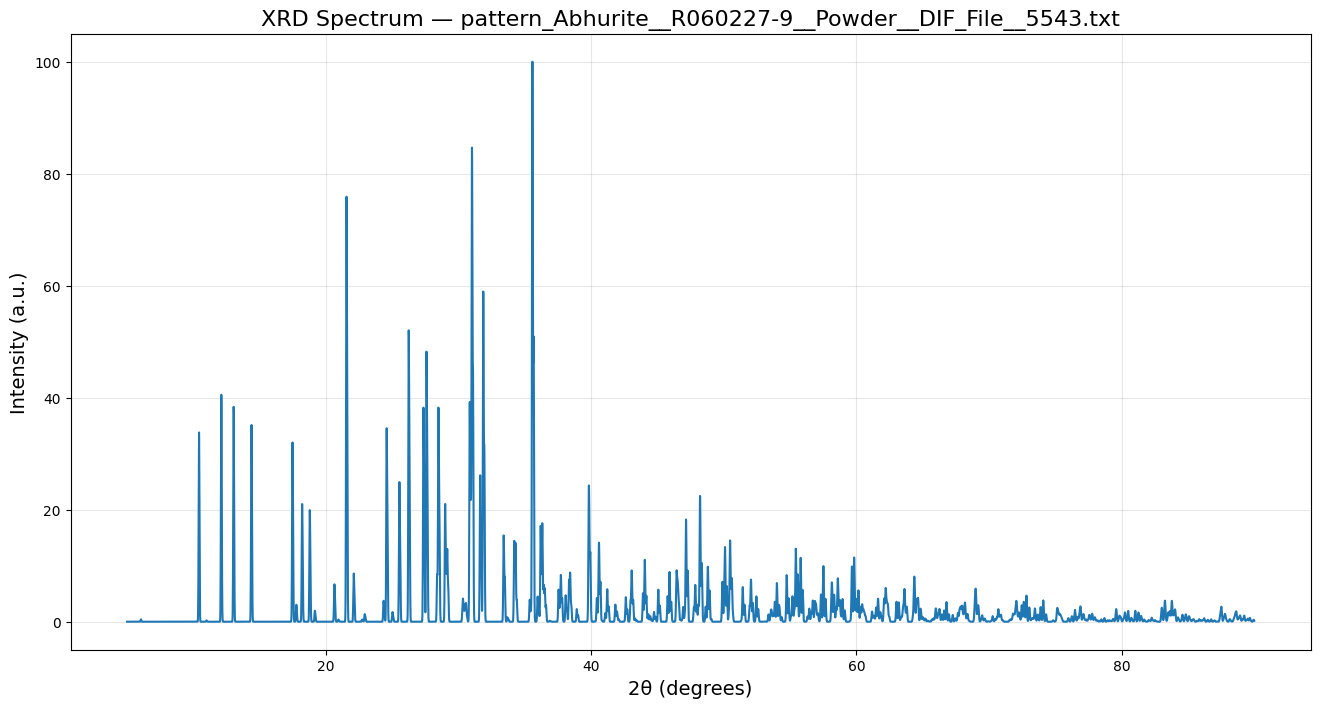

In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt


with h5py.File(file_path, "r") as f:
    base = "pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt"
    if f"{base}/2theta" in f and f"{base}/intensity" in f:
        two_theta = f[f"{base}/2theta"][()]
        intensity = f[f"{base}/intensity"][()]

        plt.figure(figsize=(16, 8))
        plt.plot(two_theta, intensity, color='tab:blue', linewidth=1.5)
        plt.title(f"XRD Spectrum — {base}", fontsize=16)
        plt.xlabel("2θ (degrees)", fontsize=14)
        plt.ylabel("Intensity (a.u.)", fontsize=14)
        plt.grid(True, alpha=0.3)
        plt.show()
    else:
        print(f"❌ Missing 2θ or intensity dataset under {base}")


In [ ]:
import h5py
import numpy as np
import pandas as pd

#file_path = "your_file.hdf5"  # change this

intensity_stats = []

def summarize_intensity(name, obj):
    # Only include datasets ending in "intensity"
    if isinstance(obj, h5py.Dataset) and name.endswith("/intensity"):
        data = obj[()]
        if data.size == 0:
            return
        stats = {
            "path": name,
            "size": data.size,
            "min": np.nanmin(data),
            "max": np.nanmax(data),
            "mean": np.nanmean(data),
            "std": np.nanstd(data),
            "nan_count": np.isnan(data).sum(),
        }
        intensity_stats.append(stats)

# Traverse recursively
with h5py.File(file_path, "r") as f:
    f.visititems(summarize_intensity)

# Convert to DataFrame
df = pd.DataFrame(intensity_stats)

# --- Print summary ---
print(f"📈 Total intensity datasets found: {len(df)}\n")
print("🧩 Per-dataset statistics (first few):")
print(df.head())

print("\n📊 Global summary across all intensity datasets:")
print(df.describe())

# Optional: check for NaNs across all spectra
total_nans = df["nan_count"].sum()
print(f"\n🔍 Total NaN values across all intensity datasets: {total_nans}")


📈 Total intensity datasets found: 1248

🧩 Per-dataset statistics (first few):
                                                path  size  min    max  \
0  pattern_Abhurite__R060227-9__Powder__DIF_File_...  8501  0.0  100.0   
1  pattern_Acanthite__R070578-9__Powder__DIF_File...  8501  0.0  100.0   
2  pattern_Actinolite__R120010-9__Powder__DIF_Fil...  8501  0.0  100.0   
3  pattern_Adelite__R060687-9__Powder__DIF_File__...  8501  0.0  100.0   
4  pattern_Adelite__R140962-9__Powder__DIF_File__...  8501  0.0  100.0   

       mean       std  nan_count  
0  2.145054  6.399756          0  
1  2.802820  8.619971          0  
2  1.912796  6.129705          0  
3  1.094515  4.513772          0  
4  1.716814  5.733322          0  

📊 Global summary across all intensity datasets:
              size          min          max         mean          std  \
count  1248.000000  1248.000000  1248.000000  1248.000000  1248.000000   
mean   8468.166667     0.002404   138.752404     1.662271     6.300811

## Label Inspection

In [ ]:
import h5py

def list_attributes(name, obj):
    # If this object has attributes, print them
    if len(obj.attrs) > 0:
        print(f"\n📁 Path: {name}")
        for key, value in obj.attrs.items():
            print(f"  ├─ {key}: {value}")

with h5py.File(file_path, "r") as f:
    print(f"📘 Exploring attributes in: {file_path}")
    print("=" * 80)
    f.visititems(list_attributes)
    print("\n✅ Attribute listing complete.")


📘 Exploring attributes in: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg.hdf5

📁 Path: pattern_Abhurite__R060227-9__Powder__DIF_File__5543.txt
  ├─ eg: 75

📁 Path: pattern_Acanthite__R070578-9__Powder__DIF_File__11911.txt
  ├─ eg: 4

📁 Path: pattern_Actinolite__R120010-9__Powder__DIF_File__10992.txt
  ├─ eg: 5

📁 Path: pattern_Adelite__R060687-9__Powder__DIF_File__7037.txt
  ├─ eg: 10

📁 Path: pattern_Adelite__R140962-9__Powder__DIF_File__12190.txt
  ├─ eg: 10

📁 Path: pattern_Aegirine__R061093-9__Powder__DIF_File__11401.txt
  ├─ eg: 6

📁 Path: pattern_Aegirine__R070125-9__Powder__DIF_File__11403.txt
  ├─ eg: 6

📁 Path: pattern_Aegirine__R070253-9__Powder__DIF_File__10353.txt
  ├─ eg: 6

📁 Path: pattern_Aegirine__R120144-9__Powder__DIF_File__11373.txt
  ├─ eg: 6

📁 Path: pattern_Aegirine__R120167-9__Powder__DIF_File__11389.txt
  ├─ eg: 6

📁 Path: pattern_Afghanite__R060422-1__Powder__DIF_File__3613.txt
  ├─ eg: 73

📁 Path: pattern_Afghanite__R07

Histogram per Label

In [5]:
import h5py
from collections import defaultdict
import numpy as np

#file_path = "data.h5"   # <-- change this

# Histogram: attr_name -> {value -> count}
attribute_hist = defaultdict(lambda: defaultdict(int))


def normalize_value(val):
    """Convert HDF5 attribute values into hashable Python types."""
    if isinstance(val, bytes):
        return val.decode("utf-8")

    if isinstance(val, np.ndarray):
        # Small arrays (e.g., label vectors) → tuple
        if val.size <= 20:
            return tuple(val.tolist())
        return f"<array shape={val.shape}>"

    if isinstance(val, np.generic):
        return val.item()

    return val


def collect_attributes(name, obj):
    if len(obj.attrs) == 0:
        return

    for key, value in obj.attrs.items():
        norm_val = normalize_value(value)
        attribute_hist[key][norm_val] += 1


# ------------------------------------------------------------------
# Traverse file
# ------------------------------------------------------------------
with h5py.File(file_path, "r") as f:
    print(f"📘 Collecting attribute histograms from: {file_path}")
    print("=" * 80)
    f.visititems(collect_attributes)

# ------------------------------------------------------------------
# Print histograms
# ------------------------------------------------------------------
print("\n" + "=" * 80)
print("📊 ATTRIBUTE HISTOGRAMS")
print("=" * 80)

for attr, counts in attribute_hist.items():
    print(f"\n🔑 Attribute: {attr}")
    print("-" * 60)

    for val, cnt in sorted(counts.items(), key=lambda x: x[1], reverse=True):
        print(f"{val!r:30} : {cnt}")

print("\n✅ Attribute histogram complete.")


📘 Collecting attribute histograms from: /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg.hdf5

📊 ATTRIBUTE HISTOGRAMS

🔑 Attribute: eg
------------------------------------------------------------
4                              : 153
17                             : 121
5                              : 112
99                             : 107
6                              : 98
75                             : 75
2                              : 55
77                             : 41
73                             : 40
71                             : 34
29                             : 32
22                             : 23
10                             : 22
76                             : 21
21                             : 21
93                             : 20
63                             : 20
3                              : 19
97                             : 17
18                             : 14
12                             : 13
80    

## Pattern Length Uniformity Check

In [ ]:
import collections

lengths = []
length_to_keys = collections.defaultdict(list)

with h5py.File(file_path, "r") as f:
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        if "intensity" not in group:
            continue

        intensity = group["intensity"][:]
        L = len(intensity)

        lengths.append(L)
        length_to_keys[L].append(key)

# basic stats
lengths = np.array(lengths)

print("Total spectra:", len(lengths))
print("Min length:", lengths.min())
print("Max length:", lengths.max())
print("Unique lengths:", np.unique(lengths))


Total spectra: 1248
Min length: 1536
Max length: 8501
Unique lengths: [1536 1701 8498 8499 8500 8501]


In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt

min_len = float("inf")
min_keys = []

with h5py.File(file_path, "r") as f:
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue
        if "intensity" not in group:
            continue

        L = len(group["intensity"])

        if L < min_len:
            min_len = L
            min_keys = [key]
        elif L == min_len:
            min_keys.append(key)

print(f"Minimum length: {min_len}")
print("Keys:", min_keys)


Minimum length: 1536
Keys: ['pattern_Waylandite__R130361-9__Powder__DIF_File__11928.txt']


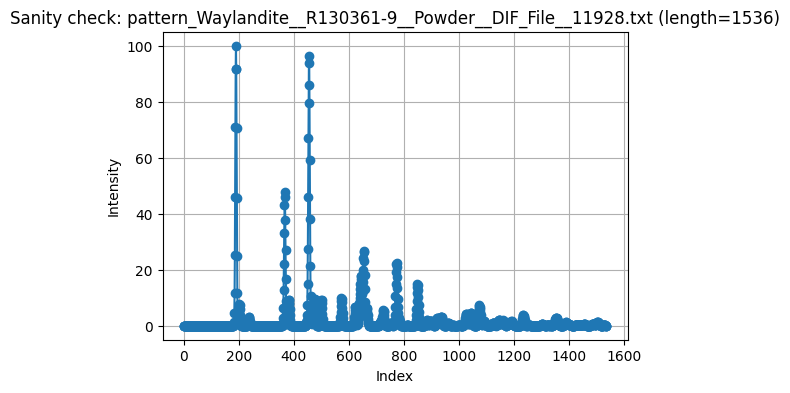

In [ ]:
with h5py.File(file_path, "r") as f:
    for key in min_keys:
        intensity = f[key]["intensity"][:]

        plt.figure(figsize=(6, 4))
        plt.plot(intensity, marker="o")
        plt.title(f"Sanity check: {key} (length={len(intensity)})")
        plt.xlabel("Index")
        plt.ylabel("Intensity")
        plt.grid(True)
        plt.show()


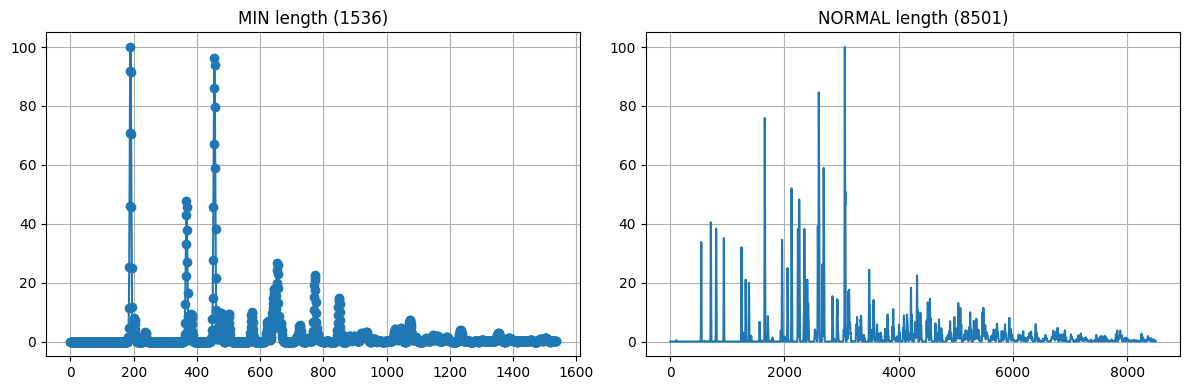

In [ ]:
# find a representative "normal" spectrum (~8501)
with h5py.File(file_path, "r") as f:
    for key in f.keys():
        if "intensity" in f[key] and len(f[key]["intensity"]) >= 8500:
            normal_key = key
            break

    min_intensity = f[min_keys[0]]["intensity"][:]
    normal_intensity = f[normal_key]["intensity"][:]

plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(min_intensity, marker="o")
plt.title(f"MIN length ({len(min_intensity)})")
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(normal_intensity)
plt.title(f"NORMAL length ({len(normal_intensity)})")
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
import h5py
import numpy as np
import matplotlib.pyplot as plt
from collections import Counter

lengths = []

with h5py.File(file_path, "r") as f:
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue
        if "intensity" not in group:
            continue

        lengths.append(len(group["intensity"]))

lengths = np.array(lengths)


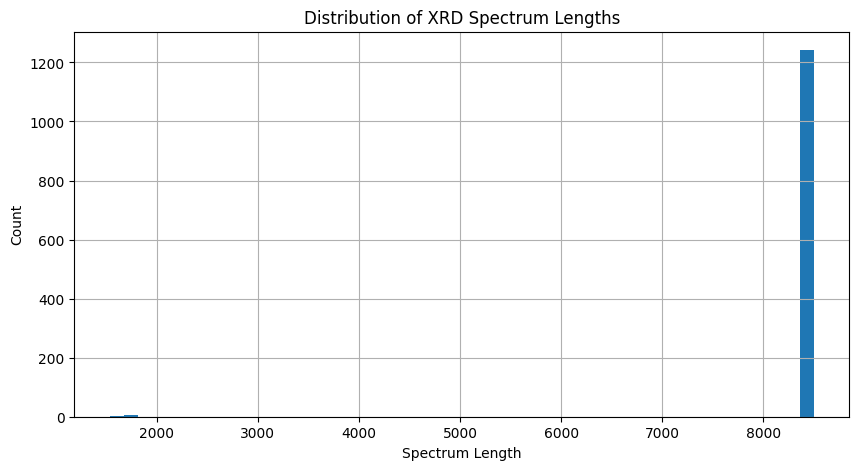

In [ ]:
plt.figure(figsize=(10, 5))
plt.hist(lengths, bins=50)
plt.xlabel("Spectrum Length")
plt.ylabel("Count")
plt.title("Distribution of XRD Spectrum Lengths")
plt.grid(True)
plt.show()


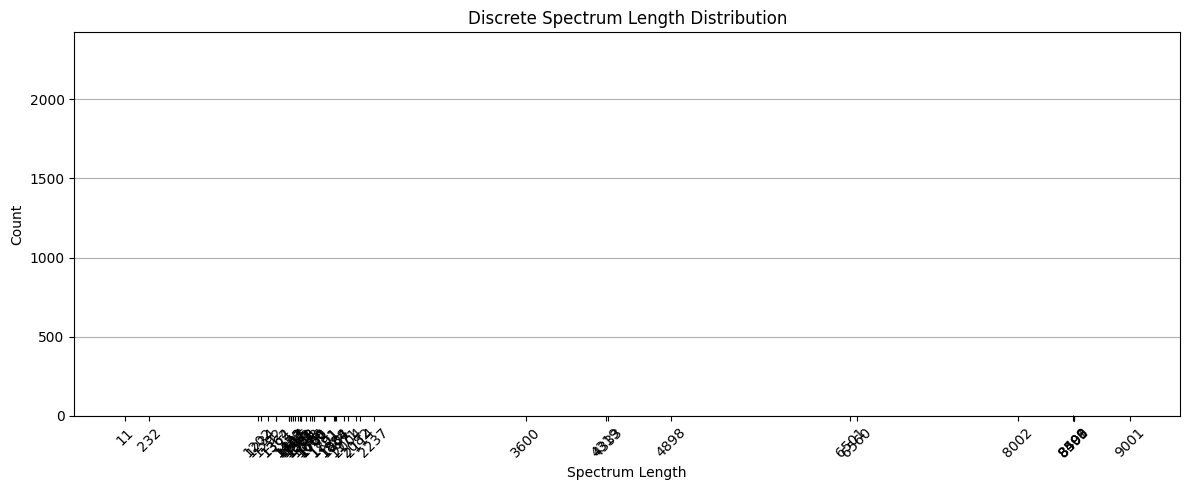

In [ ]:
length_counts = Counter(lengths)

plt.figure(figsize=(12, 5))
plt.bar(length_counts.keys(), length_counts.values())
plt.xlabel("Spectrum Length")
plt.ylabel("Count")
plt.title("Discrete Spectrum Length Distribution")
plt.xticks(sorted(length_counts.keys()), rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()


In [ ]:
import h5py
from collections import Counter

lengths = []

with h5py.File(file_path, "r") as f:
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue
        if "intensity" not in group:
            continue

        lengths.append(len(group["intensity"]))

length_counts = Counter(lengths)

print("Exact spectrum length counts:\n")
for length in sorted(length_counts):
    print(f"Length {length:5d} : {length_counts[length]:4d}")


Exact spectrum length counts:

Length  1536 :    1
Length  1701 :    5
Length  8498 :    1
Length  8499 :    1
Length  8500 :    6
Length  8501 : 1234


# Pre-processing

## Uniform Sampling

In [ ]:
import h5py
import numpy as np

# open the source file
with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    # iterate through all top-level groups (e.g., Hastingsite__R070124-1__8096)
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        # ensure intensity dataset exists
        if "intensity" not in group:
            print(f"Skipping {key}, no intensity dataset")
            continue

        # load full intensity (length ~8501)
        intensity = group["intensity"][:]

        # compute uniform sampling indices
        n_points = 1000
        idx = np.linspace(0, len(intensity) - 1, n_points, dtype=int)
        sampled = intensity[idx]

        X_list.append(sampled)

        # extract attribute value (e.g., group.attrs["eg"])
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            # fallback: if there’s only one attribute, use it
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                print(f"No valid attribute found for {key}")
                continue

        y_list.append(y_value)

    # convert to numpy arrays
    X_test = np.array(X_list)
    y_test = np.array(y_list)

# save into a new compact file
file_name_sampled = "RRUFF_norm_uniform_sampling_5_90_deg_1000_intensity.hdf5"
file_path_sampled = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_sampled}"

with h5py.File(file_path_sampled, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved {len(X_test)} samples to {file_path_sampled}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


✅ Saved 2795 samples to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_uniform_sampling_5_90_deg_1000_intensity.hdf5
Shape: X_test=(2795, 1000), y_test=(2795,)


## Pre-processing with No Sampling (Full Spectrum), Dropped Irregular Spectrum Lengths and Intensities > 1,000

In [6]:
import h5py
import numpy as np

TARGET_LENGTH = 8501
INTENSITY_MAX = 1000  # 🔴 NEW THRESHOLD

with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    kept = 0
    dropped = 0

    # iterate through all top-level groups
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        # ensure intensity dataset exists
        if "intensity" not in group:
            dropped += 1
            continue

        intensity = group["intensity"][:]

        # 🔴 hard length filter
        if len(intensity) != TARGET_LENGTH:
            dropped += 1
            continue

        # 🔴 NEW: drop if ANY intensity exceeds threshold
        if np.any(intensity > INTENSITY_MAX):
            dropped += 1
            continue

        # extract attribute value
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                dropped += 1
                continue

        X_list.append(intensity)
        y_list.append(y_value)
        kept += 1

    # safe stacking
    X_test = np.stack(X_list, axis=0)
    y_test = np.array(y_list)

print(f"Kept spectra   : {kept}")
print(f"Dropped spectra: {dropped}")
print(f"Final shape    : X_test={X_test.shape}, y_test={y_test.shape}")


# save into a new file (full-resolution spectra)
file_name_full = "RRUFF_low_bkg_full_intensity_cleaned.hdf5"
file_path_full = (
    f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"
    f"{file_name_full}"
)

with h5py.File(file_path_full, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved {len(X_test)} samples to {file_path_full}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


Kept spectra   : 1222
Dropped spectra: 26
Final shape    : X_test=(1222, 8501), y_test=(1222,)
✅ Saved 1222 samples to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg_full_intensity_cleaned.hdf5
Shape: X_test=(1222, 8501), y_test=(1222,)


Pre-processing with Per Spectrum Max Normalization

In [10]:
import h5py
import numpy as np

TARGET_LENGTH = 8501
INTENSITY_MAX = 1000  # threshold

with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    kept = 0
    dropped = 0

    # iterate through all top-level groups
    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        # ensure intensity dataset exists
        if "intensity" not in group:
            dropped += 1
            continue

        intensity = group["intensity"][:]

        # hard length filter
        if len(intensity) != TARGET_LENGTH:
            dropped += 1
            continue

        # drop if ANY intensity exceeds threshold
        if np.any(intensity > INTENSITY_MAX):
            dropped += 1
            continue

        # extract attribute value
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                dropped += 1
                continue

        X_list.append(intensity)
        y_list.append(y_value)
        kept += 1

    # safe stacking
    X_test = np.stack(X_list, axis=0).astype(np.float32)
    y_test = np.array(y_list)

# --------------------------------------------------
# 🔴 NEW: Per-spectrum max normalization
# --------------------------------------------------
max_vals = X_test.max(axis=1, keepdims=True)

# avoid division by zero (extra safety)
max_vals[max_vals == 0] = 1.0

X_test = X_test / max_vals

print(f"Kept spectra   : {kept}")
print(f"Dropped spectra: {dropped}")
print(f"Final shape    : X_test={X_test.shape}, y_test={y_test.shape}")
print(f"Post-norm max  : {X_test.max():.3f}")


# save into a new file (normalized full-resolution spectra)
file_name_full = "RRUFF_low_bkg_full_intensity_cleaned_maxnorm.hdf5"
file_path_full = (
    f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"
    f"{file_name_full}"
)

with h5py.File(file_path_full, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved {len(X_test)} samples to {file_path_full}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


Kept spectra   : 1222
Dropped spectra: 26
Final shape    : X_test=(1222, 8501), y_test=(1222,)
Post-norm max  : 1.000
✅ Saved 1222 samples to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_low_bkg_full_intensity_cleaned_maxnorm.hdf5
Shape: X_test=(1222, 8501), y_test=(1222,)


In [8]:
# --------------------------------------------------
# 🔍 Inspect head of X_test and y_test
# --------------------------------------------------
N_HEAD = 10        # number of samples to preview
N_POINTS = 10    # number of intensity values per spectrum

print("\n🔍 X_test head:")
for i in range(min(N_HEAD, len(X_test))):
    print(f"Sample {i} | first {N_POINTS} intensity values:")
    print(X_test[i][:N_POINTS])

print("\n🔍 y_test head:")
for i in range(min(N_HEAD, len(y_test))):
    print(f"Sample {i} | y = {y_test[i]}")



🔍 X_test head:
Sample 0 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 1 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 2 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 3 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 4 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 5 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 6 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 7 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 8 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
Sample 9 | first 10 intensity values:
[0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]

🔍 y_test head:
Sample 0 | y = 75
Sample 1 | y = 4
Sample 2 | y = 5
Sample 3 | y = 10
Sample 4 | y = 10
Sample 5 | y = 6
Sample 6 | y = 6
Sample 7 | y = 6
Sample 8 | y = 6
Sample 9 | y = 6


Summary Statistics - Cleaned Datasets

In [11]:
import numpy as np

# --------------------------------------------------
# 📊 Summary statistics for X_test
# --------------------------------------------------
print("\n" + "=" * 80)
print("📊 X_test SUMMARY STATISTICS")
print("=" * 80)

print(f"Shape        : {X_test.shape}")
print(f"Dtype        : {X_test.dtype}")

print("\nGlobal intensity statistics (across ALL spectra):")
print(f"  Min        : {np.min(X_test):.6f}")
print(f"  Max        : {np.max(X_test):.6f}")
print(f"  Mean       : {np.mean(X_test):.6f}")
print(f"  Std        : {np.std(X_test):.6f}")

print("\nPer-spectrum statistics (distribution over samples):")
per_spec_mean = X_test.mean(axis=1)
per_spec_std = X_test.std(axis=1)
per_spec_max = X_test.max(axis=1)

print(f"  Mean of means : {per_spec_mean.mean():.6f}")
print(f"  Std of means  : {per_spec_mean.std():.6f}")
print(f"  Mean std      : {per_spec_std.mean():.6f}")
print(f"  Max intensity : {per_spec_max.max():.6f}")

# --------------------------------------------------
# 📈 Distribution statistics for y_test
# --------------------------------------------------
print("\n" + "=" * 80)
print("📈 y_test DISTRIBUTION")
print("=" * 80)

print(f"Shape        : {y_test.shape}")
print(f"Dtype        : {y_test.dtype}")

print("\nBasic statistics:")
print(f"  Min        : {np.min(y_test):.6f}")
print(f"  Max        : {np.max(y_test):.6f}")
print(f"  Mean       : {np.mean(y_test):.6f}")
print(f"  Std        : {np.std(y_test):.6f}")

print("\nPercentiles:")
for p in [1, 5, 25, 50, 75, 95, 99]:
    print(f"  {p:>2}th percentile : {np.percentile(y_test, p):.6f}")

# --------------------------------------------------
# Optional sanity checks
# --------------------------------------------------
print("\nSanity checks:")
print(f"  NaNs in X_test : {np.isnan(X_test).sum()}")
print(f"  NaNs in y_test : {np.isnan(y_test).sum()}")



📊 X_test SUMMARY STATISTICS
Shape        : (1222, 8501)
Dtype        : float32

Global intensity statistics (across ALL spectra):
  Min        : 0.000000
  Max        : 1.000000
  Mean       : 0.012891
  Std        : 0.052900

Per-spectrum statistics (distribution over samples):
  Mean of means : 0.012891
  Std of means  : 0.008685
  Mean std      : 0.050537
  Max intensity : 1.000000

📈 y_test DISTRIBUTION
Shape        : (1222,)
Dtype        : int64

Basic statistics:
  Min        : 1.000000
  Max        : 99.000000
  Mean       : 37.523732
  Std        : 35.364513

Percentiles:
   1th percentile : 2.000000
   5th percentile : 3.000000
  25th percentile : 5.000000
  50th percentile : 17.000000
  75th percentile : 75.000000
  95th percentile : 99.000000
  99th percentile : 99.000000

Sanity checks:
  NaNs in X_test : 0
  NaNs in y_test : 0


In [ ]:
import h5py
import numpy as np

TARGET_LENGTH = 8501

with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    kept = 0
    dropped = 0

    # lists to store dropped indices, keys, and reasons
    dropped_indices = []
    dropped_keys = []
    dropped_reasons = []

    # iterate through all top-level groups
    for idx, key in enumerate(f.keys()):
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        # ensure intensity dataset exists
        if "intensity" not in group:
            dropped += 1
            dropped_indices.append(idx)
            dropped_keys.append(key)
            dropped_reasons.append("missing_intensity")
            continue

        intensity = group["intensity"][:]

        # 🔴 hard length filter
        if len(intensity) != TARGET_LENGTH:
            dropped += 1
            dropped_indices.append(idx)
            dropped_keys.append(key)
            dropped_reasons.append(f"length_{len(intensity)}")
            continue

        # extract attribute value
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                dropped += 1
                dropped_indices.append(idx)
                dropped_keys.append(key)
                dropped_reasons.append("missing_label")
                continue

        X_list.append(intensity)
        y_list.append(y_value)
        kept += 1

    # safe stacking
    X_test = np.stack(X_list, axis=0)
    y_test = np.array(y_list)

print(f"Kept spectra   : {kept}")
print(f"Dropped spectra: {dropped}")
print(f"Final shape    : X_test={X_test.shape}, y_test={y_test.shape}")

# output all dropped indices
print("\nAll dropped spectra:")
for idx, key, reason in zip(dropped_indices, dropped_keys, dropped_reasons):
    print(f"Index {idx:4d} | Key: {key} | Reason: {reason}")

# output dropped indices as a Python list
print("\nDropped indices list:")
print(dropped_indices)

# save into a new file (full-resolution spectra)
file_name_full = "RRUFF_low_bkg_full_intensity.hdf5"
file_path_full = (
    f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"
    f"{file_name_full}"
)

with h5py.File(file_path_full, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved {len(X_test)} samples to {file_path_full}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


Kept spectra   : 1234
Dropped spectra: 14
Final shape    : X_test=(1234, 8501), y_test=(1234,)

All dropped spectra:
Index   44 | Key: pattern_Anhydrite__R040012-1__Powder__DIF_File__3016.txt | Reason: length_8500
Index   45 | Key: pattern_Anhydrite__R040061-1__Powder__DIF_File__3293.txt | Reason: length_8500
Index  191 | Key: pattern_Calcite__R040170-1__Powder__DIF_File__3895.txt | Reason: length_8498
Index  208 | Key: pattern_Cassiterite__R040072-1__Powder__DIF_File__3339.txt | Reason: length_8500
Index  399 | Key: pattern_Ferrofettelite__R100124-9__Powder__DIF_File__12663.txt | Reason: length_1701
Index  436 | Key: pattern_Fluorite__R040099-1__Powder__DIF_File__3431.txt | Reason: length_8500
Index  481 | Key: pattern_Giniite__R060765-9__Powder__DIF_File__12645.txt | Reason: length_1701
Index  616 | Key: pattern_Khinite__R080124-9__Powder__DIF_File__9860.txt | Reason: length_1701
Index  763 | Key: pattern_Mikenewite__R210021-9__Powder__DIF_File__12688.txt | Reason: length_1701
Index 

Reduced Range

In [ ]:
import h5py
import numpy as np

# Path to your original HDF5 file
#h5_path = "your_file.hdf5"

# Full measurement range (from metadata or known acquisition setup)
theta_min, theta_max = 5.0, 90.0
target_min, target_max = 10.0, 80.0

# open the file and process
with h5py.File(file_path, "r") as f:
    X_list = []
    y_list = []

    for key in f.keys():
        group = f[key]
        if not isinstance(group, h5py.Group):
            continue

        if "intensity" not in group:
            print(f"Skipping {key}, no intensity dataset")
            continue

        intensity = group["intensity"][:]
        n_points = len(intensity)

        # create synthetic 2θ grid across [5°, 90°]
        two_theta = np.linspace(theta_min, theta_max, n_points)

        # select only the range [10°, 80°]
        mask = (two_theta >= target_min) & (two_theta <= target_max)
        reduced_intensity = intensity[mask]
        reduced_theta = two_theta[mask]

        # (optional) resample to 1000 uniform points across 10–80°
        n_target = 701
        new_theta = np.linspace(target_min, target_max, n_target)
        sampled_intensity = np.interp(new_theta, reduced_theta, reduced_intensity)

        X_list.append(sampled_intensity)

        # get label (attribute)
        if "eg" in group.attrs:
            y_value = group.attrs["eg"]
        else:
            attrs = list(group.attrs.items())
            if len(attrs) == 1:
                y_value = attrs[0][1]
            else:
                print(f"No valid attribute for {key}")
                continue

        y_list.append(y_value)

    X_test = np.array(X_list)
    y_test = np.array(y_list)

# save into a new compact reduced range file
file_name_reduced = "RRUFF_norm_reduced_range_10_80_deg_701_intensity.hdf5"
file_path_reduced = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name_reduced}"

with h5py.File(file_path_reduced, "w") as f_out:
    f_out.create_dataset("X_test", data=X_test)
    f_out.create_dataset("y_test", data=y_test)

print(f"✅ Saved reduced-range samples to {file_path_reduced}")
print(f"Shape: X_test={X_test.shape}, y_test={y_test.shape}")


✅ Saved reduced-range samples to /content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_reduced_range_10_80_deg_701_intensity.hdf5
Shape: X_test=(2795, 701), y_test=(2795,)


X_test shape: (2795, 701)
y_test shape: (2795,)
Unique labels: [ 1  2  3  4  5  6  7  9 10 11 12 14 15 16 17 18 19 21 22 23 24 26 28 29
 30 31 32 33 34 35 37 38 39 40 41 42 44 45 46 47 48 49 51 52 53 54 55 58
 60 62 63 65 68 69 70 71 72 73 74 75 76 77 80 81 82 85 86 87 89 90 91 92
 93 94 95 97 98 99]

📊 Intensity Summary Statistics:
        mean        std  min          max
0  34.852527  86.769922  0.0   968.610000
1  33.833150  84.779283  0.0  1000.000000
2  36.352481  95.051846  0.0  1000.000000
3  34.593515  88.021392  0.0  1000.000000
4  36.982103  92.980518  0.0   976.049412

🧾 Label Distribution:
    count
1       5
2      89
3      41
4     314
5     242
..    ...
94     52
95      2
97     70
98      1
99    279

[78 rows x 1 columns]


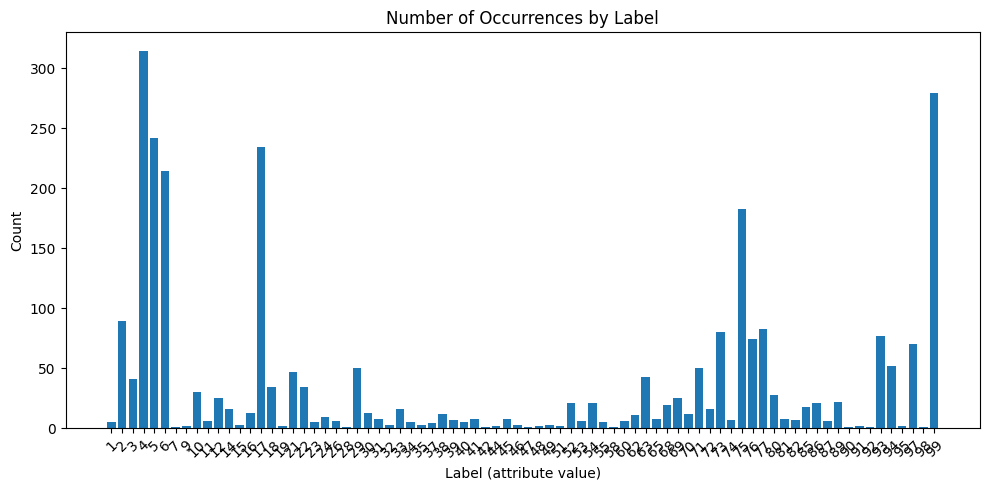

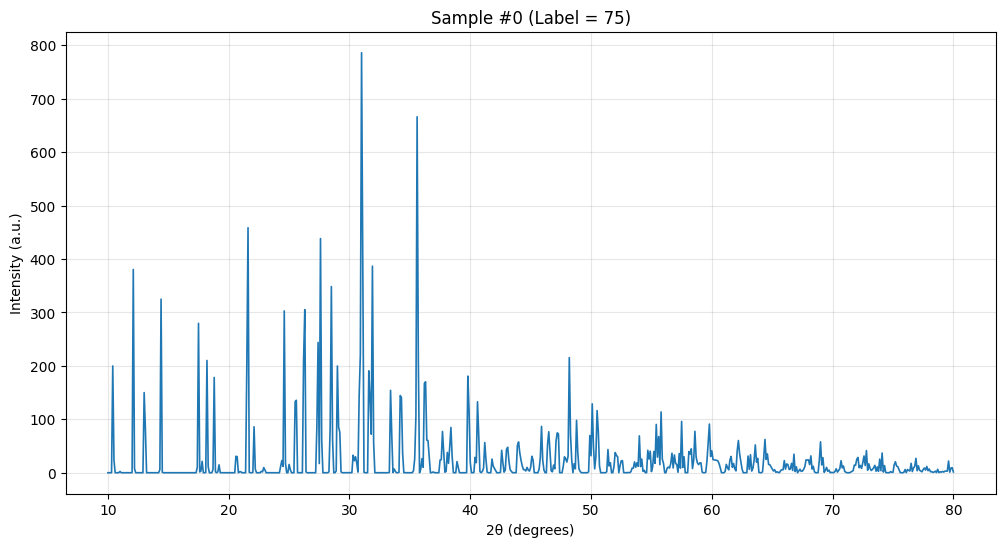

In [ ]:
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

# Path to your reduced dataset
#file_path_reduced = "intensity_test_data_10_80deg.hdf5"

with h5py.File(file_path_reduced, "r") as f:
    X_test = f["X_test"][:]
    y_test = f["y_test"][:]

# -----------------------------
# 🧩 Basic Info
# -----------------------------
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")
print(f"Unique labels: {np.unique(y_test)}")

# Summary statistics
df_stats = pd.DataFrame(X_test)
summary = df_stats.describe().T[["mean", "std", "min", "max"]]
print("\n📊 Intensity Summary Statistics:")
print(summary.head())

# -----------------------------
# 🧮 Label Distribution
# -----------------------------
label_counts = Counter(y_test)
label_df = pd.DataFrame.from_dict(label_counts, orient="index", columns=["count"])
label_df = label_df.sort_index()

print("\n🧾 Label Distribution:")
print(label_df)

plt.figure(figsize=(10, 5))
plt.bar(label_df.index.astype(str), label_df["count"])
plt.xlabel("Label (attribute value)")
plt.ylabel("Count")
plt.title("Number of Occurrences by Label")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# -----------------------------
# 📈 Plot a sample intensity spectrum
# -----------------------------
sample_idx = 0  # change this to view a different sample
n_points = X_test.shape[1]
two_theta = np.linspace(10, 80, n_points)

plt.figure(figsize=(12, 6))
plt.plot(two_theta, X_test[sample_idx], lw=1.2)
plt.title(f"Sample #{sample_idx} (Label = {y_test[sample_idx]})")
plt.xlabel("2θ (degrees)")
plt.ylabel("Intensity (a.u.)")
plt.grid(True, alpha=0.3)
plt.show()


In [ ]:
import h5py
import numpy as np

def ensure_splits_exist(h5_path):
    with h5py.File(h5_path, "a") as f:
        # Check if test split exists to copy metadata
        if "X_test" not in f:
            raise ValueError("No 'X_test' found — cannot infer shape for empty splits.")

        x_shape = f["X_test"].shape[1]  # number of intensity points
        dtype = f["X_test"].dtype

        # Define shape for empty splits (0 samples, same feature width)
        empty_shape = (0, x_shape)
        y_dtype = f["y_test"].dtype

        # Create X_train and y_train if missing
        if "X_train" not in f:
            f.create_dataset("X_train", shape=empty_shape, dtype=dtype)
            print("✅ Created empty X_train")

        if "y_train" not in f:
            f.create_dataset("y_train", shape=(0,), dtype=y_dtype)
            print("✅ Created empty y_train")

        # Create X_val and y_val if missing
        if "X_val" not in f:
            f.create_dataset("X_val", shape=empty_shape, dtype=dtype)
            print("✅ Created empty X_val")

        if "y_val" not in f:
            f.create_dataset("y_val", shape=(0,), dtype=y_dtype)
            print("✅ Created empty y_val")

    print(f"✅ File '{h5_path}' is now compatible with all splits.")


In [ ]:
ensure_splits_exist(file_path_reduced)


✅ Created empty X_train
✅ Created empty y_train
✅ Created empty X_val
✅ Created empty y_val
✅ File '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_reduced_range_10_80_deg_701_intensity.hdf5' is now compatible with all splits.


In [ ]:
ensure_splits_exist(file_path_sampled)

✅ Created empty X_train
✅ Created empty y_train
✅ Created empty X_val
✅ Created empty y_val
✅ File '/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/RRUFF_norm_uniform_sampling_5_90_deg_1000_intensity.hdf5' is now compatible with all splits.


# Interpretability Data

In [ ]:
file_name = "RRUFF_interp_data.hdf5"
file_path = f"/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/{file_name}"
data_path = "/content/drive/MyDrive/Research/OrgA/OrgA Team Shared Folder/Data - HDF5/"